# Agri-Vision4 — Exploratory Data Analysis
### Multi-Crop Leaf Disease Dataset (Tomato, Papaya, Zucchini, Bottle Gourd)

This notebook explores the **Agri-Vision4** dataset: a collection of leaf images
for four crops, each with several disease/health classes, provided as both
**Original** (raw, expert-validated) and **Augmented** image sets.

**What this notebook does:**
1. Auto-discovers the dataset folder structure (robust to minor naming differences
   between the README and the actual Kaggle folder names).
2. Counts images per crop / class / original-vs-augmented.
3. Inspects image properties (dimensions, file size, aspect ratio, color channels).
4. Analyzes pixel-level statistics (brightness, color distribution, sharpness) as a
   proxy for image quality and to spot outliers / corrupted files.
5. Visualizes sample images per class and compares original vs augmented samples.
6. Checks for class imbalance and duplicate/corrupt files.

Every plot is **displayed inline** (`plt.show()`) and also **saved to disk** under
`./eda_outputs/` so the figures are available as standalone files too.\n\n> **Update:** this revision runs all integrity / duplicate / dimension checks over the **entire dataset** (not a sample), and adds a dedicated **Original-vs-Augmented data-leakage check** (Section 5.2) using perceptual hashing. Sampling is now used only where it's statistically appropriate (pixel-level brightness/contrast/sharpness stats).

In [1]:
import os
import sys
import glob
import json
import random
import hashlib
import warnings
import subprocess
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from PIL import Image, ImageStat

# imagehash is used later for the Original-vs-Augmented near-duplicate /
# data-leakage check. It is not always preinstalled, so install it on the
# fly if missing rather than failing the whole notebook.
try:
    import imagehash
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imagehash"], check=False)
    import imagehash

# tqdm gives a progress bar on the full-dataset passes (28k+ images), which
# matters here since several cells below now iterate over every image
# instead of a sample. Falls back to a no-op wrapper if unavailable.
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **kwargs):
        return iterable

warnings.filterwarnings("ignore")

# Plot style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titleweight"] = "bold"

RNG_SEED = 42
random.seed(RNG_SEED)
np.random.seed(RNG_SEED)

OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tiff"}


# ── Width of the divider line used by all print helpers ──────────────────
_DIVW = 72

def _shorten_path(p, max_len=45):
    """Keep just the last few path components so long Kaggle paths fit in a table."""
    from pathlib import PurePath
    parts = PurePath(str(p)).parts
    result = str(p)
    while len(result) > max_len and len(parts) > 2:
        parts = parts[1:]
        result = "…/" + "/".join(parts[1:]) if len(parts) > 1 else parts[0]
    return result


def _format_df_for_print(df, max_rows=30, path_cols=None):
    """
    Return a copy of df ready to print:
    - Truncate to max_rows
    - Shorten any path-like columns so lines stay readable
    - Reset index for cleaner numbering
    """
    import pandas as _pd
    out = df.head(max_rows).copy().reset_index(drop=True)
    if path_cols is None:
        path_cols = [c for c in out.columns if "path" in str(c).lower()]
    for col in path_cols:
        if col in out.columns:
            out[col] = out[col].astype(str).map(_shorten_path)
    return out


def print_table(title, dataframe_or_series, max_rows=30):
    """
    Print a clearly-labelled text version of whatever a plot is about to
    show, directly to stdout. Every figure-producing cell below calls this
    BEFORE plt.show(), so the underlying numbers are always visible in the
    terminal/output log even if the image itself doesn't render.
    Path columns are automatically shortened so lines don't run off-screen.
    """
    import pandas as _pd
    print("─" * _DIVW)
    print(title)
    print("─" * _DIVW)
    if isinstance(dataframe_or_series, _pd.DataFrame):
        print(_format_df_for_print(dataframe_or_series, max_rows).to_string(index=True))
    elif isinstance(dataframe_or_series, _pd.Series):
        if len(dataframe_or_series) == 0:
            pass  # nothing to show for placeholder series
        else:
            print(dataframe_or_series.head(max_rows).to_string())
    else:
        print(dataframe_or_series)
    print()


def print_leakage_report(leak_df, threshold, max_rows=25):
    """
    Pretty-print the leakage pairs table with aligned columns and short paths.
    Shows: #, Crop, Class (without crop prefix), Dist, Original filename, Augmented filename.
    """
    if len(leak_df) == 0:
        return
    from pathlib import PurePath
    import textwrap

    def _stem(p):
        return PurePath(str(p)).name

    def _class_short(crop, cls):
        prefix = crop.replace(" ", "_") + "_"
        return cls[len(prefix):] if cls.startswith(prefix) else cls

    rows = leak_df.head(max_rows).copy().reset_index(drop=True)

    # Build display rows
    display = []
    for i, r in rows.iterrows():
        display.append({
            "#":      i + 1,
            "Crop":   r["crop"],
            "Class":  _class_short(r["crop"], r["class_name"]),
            "Dist":   r["hamming_distance"],
            "Original file":   _stem(r["original_path"]),
            "Augmented file":  _stem(r["augmented_path"]),
        })

    # Column widths
    cols = ["#", "Crop", "Class", "Dist", "Original file", "Augmented file"]
    widths = {c: len(c) for c in cols}
    for row in display:
        for c in cols:
            widths[c] = max(widths[c], len(str(row[c])))

    # Cap file name columns at 40 chars
    for fc in ["Original file", "Augmented file"]:
        widths[fc] = min(widths[fc], 40)

    def _fmt(val, col):
        s = str(val)
        w = widths[col]
        if len(s) > w:
            s = s[:w-1] + "…"
        return s.ljust(w)

    header = "  ".join(_fmt(c, c) for c in cols)
    sep    = "  ".join("─" * widths[c] for c in cols)
    print("─" * _DIVW)
    print(f"LEAKAGE PAIRS  (pHash Hamming distance ≤ {threshold})  —  "
          f"first {min(max_rows, len(leak_df))} of {len(leak_df):,}")
    print("─" * _DIVW)
    print(header)
    print(sep)
    for row in display:
        print("  ".join(_fmt(row[c], c) for c in cols))
    if len(leak_df) > max_rows:
        print(f"  … {len(leak_df) - max_rows:,} more rows not shown")
    print()


print("Libraries loaded successfully.")
print(f"Plots and figures will be saved to: {OUTPUT_DIR.resolve()}")


Libraries loaded successfully.
Plots and figures will be saved to: /kaggle/working/eda_outputs


## 1. Locate the Dataset

Kaggle notebooks mount input datasets under `/kaggle/input/<dataset-name>/...`.
The exact folder names can vary slightly (e.g. `Orginal_Dataset` vs `Original_Images`,
`Batol_Gourd` vs `Bottle_Gourd`), so instead of hardcoding paths from the README,
we **search the filesystem** for plausible dataset roots and let the user confirm/override.

In [2]:
def find_candidate_roots(search_dirs=("/kaggle/input", ".", "..")):
    """
    Search common locations for folders that directly contain image files,
    i.e. potential 'leaf' folders of a crop/class structure.
    Returns a list of (path, image_count) tuples.
    """
    candidates = []
    for base in search_dirs:
        base = Path(base)
        if not base.exists():
            continue
        for root, dirs, files in os.walk(base):
            depth = len(Path(root).relative_to(base).parts)
            if depth > 10:
                dirs[:] = []  # don't go deeper
                continue
            img_files = [f for f in files if Path(f).suffix.lower() in VALID_EXTS]
            if len(img_files) >= 3:
                candidates.append((Path(root), len(img_files)))
    return candidates


def dataset_group_key(path: Path):
    """
    Identify which 'dataset' a leaf-image folder belongs to, so that an
    unrelated second dataset attached to the same Kaggle notebook doesn't
    get merged into the search. Handles both common Kaggle layouts:
      /kaggle/input/<dataset-slug>/...                    -> group up to <dataset-slug>
      /kaggle/input/datasets/<owner>/<dataset-slug>/...   -> group up to <dataset-slug>
    """
    parts = path.parts
    if "input" in parts:
        idx = parts.index("input")
        if len(parts) > idx + 1 and parts[idx + 1] == "datasets":
            return parts[: idx + 4]  # .../input/datasets/<owner>/<dataset-slug>
        return parts[: idx + 2]      # .../input/<dataset-slug>
    return parts[:3]


def _descendant_has_split(folder: Path, target_split: str, max_depth=8):
    """Check whether `folder` has any descendant directory classified as target_split."""
    for root, dirs, files in os.walk(folder):
        rel_depth = len(Path(root).relative_to(folder).parts)
        if rel_depth > max_depth:
            dirs[:] = []
            continue
        for d in dirs:
            if classify_split(d) == target_split:
                return True
    return False


def pick_dataset_root(search_dirs=("/kaggle/input", ".", "..")):
    """
    Find the dataset root in two stages:
    1. Locate every folder that directly contains images, and group them by
       which dataset they likely belong to (so a second, unrelated attached
       dataset doesn't get merged in) -- pick the group with the most images.
    2. Within that group, find the DEEPEST common ancestor folder that still
       has both an 'Original'-like and an 'Augmented'-like descendant
       folder. Using "has both splits" (rather than just the common prefix
       of every leaf-image folder) avoids overshooting into shared
       subfolder structure -- which matters here because the Original and
       Augmented branches of this dataset nest images at different depths
       (the Augmented side has one extra wrapper level per crop).
    Falls back to the common-prefix approach if no clean split point is found.
    """
    candidates = find_candidate_roots(search_dirs)
    if not candidates:
        return None

    kaggle_candidates = [c for c, n in candidates if str(c).startswith("/kaggle/input")]
    counts = {c: n for c, n in candidates}
    pool = kaggle_candidates if kaggle_candidates else [c for c, n in candidates]

    groups = {}
    for c in pool:
        key = dataset_group_key(c)
        groups.setdefault(key, []).append(c)
    best_key = max(groups, key=lambda k: sum(counts[c] for c in groups[k]))
    group_paths = groups[best_key]

    candidate_ancestors = set()
    for leaf in group_paths:
        candidate_ancestors.update(list(leaf.parents) + [leaf])

    best_root, best_depth = None, -1
    for folder in candidate_ancestors:
        if not folder.is_dir():
            continue
        if _descendant_has_split(folder, "Original") and _descendant_has_split(folder, "Augmented"):
            depth = len(folder.parts)
            if depth > best_depth:  # prefer the deepest folder that still has both splits
                best_depth = depth
                best_root = folder

    if best_root is not None:
        return best_root

    # Fallback: common prefix of the leaf-image folders in the chosen group.
    parts_lists = [p.parts for p in group_paths]
    min_len = min(len(p) for p in parts_lists)
    common_parts = []
    for i in range(min_len):
        values_at_i = {p[i] for p in parts_lists}
        if len(values_at_i) == 1:
            common_parts.append(parts_lists[0][i])
        else:
            break
    if not common_parts:
        return group_paths[0]
    return Path(*common_parts)


# --- Try auto-detection first ---
# Note: pick_dataset_root() relies on classify_split(), defined in the next
# cell. We declare a minimal local copy here so detection works standalone
# even if cells are re-run out of order.
def classify_split(folder_name: str):
    name = folder_name.lower()
    if "aug" in name:
        return "Augmented"
    if "orig" in name or "orgin" in name or "raw" in name:
        return "Original"
    return None


DATASET_ROOT = pick_dataset_root()

# --- Manual override ---
# If auto-detection picks the wrong folder, set the path explicitly here, e.g.:
DATASET_ROOT_OVERRIDE = None  # <-- set to a string path to force a specific root
# Example for this dataset's real Kaggle path:
# DATASET_ROOT_OVERRIDE = "/kaggle/input/datasets/atkiyamaisha/multi-crop-leaf-disease-dataset"
if DATASET_ROOT_OVERRIDE:
    DATASET_ROOT = Path(DATASET_ROOT_OVERRIDE)

if DATASET_ROOT is None:
    print("Could not auto-detect a dataset root with images.")
    print("Please set DATASET_ROOT_OVERRIDE above to the correct dataset folder path.")
else:
    print(f"Detected dataset root: {DATASET_ROOT}")
    print("\nTop-level contents:")
    for item in sorted(DATASET_ROOT.iterdir()):
        print(" -", item.name)

Detected dataset root: /kaggle/input/datasets/atkiyamaisha/multi-crop-leaf-disease-dataset/Agri-Vision4 A Comprehensive Multi-Crop Leaf Disea

Top-level contents:
 - Aug_Dataset
 - Orginal_Dataset
 - README.txt


## 2. Map the Folder Tree → (Split, Crop, Class) Triples

We classify each top-level (or second-level) folder as **Original** or **Augmented**
based on naming keywords (`aug`, `orig`, `original`), then walk down to the
crop folder and finally the class folder, collecting every image path along the way.
This makes the notebook resilient to the exact folder names seen in this dataset
version (`Orginal_Dataset`, `Update_Aug_Dataset`, `Batol_Gourd`, `Zucchini_Original`,
`papaya_main_dataset`, etc.) without hardcoding them.

In [3]:
def classify_split(folder_name: str):
    """
    Classify a folder name as 'Original' or 'Augmented' based on keywords.
    Handles the common real-world misspelling 'Orginal' (missing the second 'i')
    seen in this dataset's actual folder names, in addition to 'Original'/'Orig'.
    """
    name = folder_name.lower()
    if "aug" in name:
        return "Augmented"
    if "orig" in name or "orgin" in name or "raw" in name:
        return "Original"
    return None


def make_class_label(crop_name: str, raw_class_name: str) -> str:
    """
    Build a crop-qualified class label like 'Tomato_Spot' or
    'Bottle_Gourd_Anthracnose', so class names are unique across crops and
    self-describing on their own (useful in plots, filenames, and groupby
    output where you'd otherwise see bare 'Healthy' or 'Spot' with no
    indication of which crop it belongs to).
    """
    crop_part = crop_name.strip().replace(" ", "_")
    class_part = raw_class_name.strip().replace(" ", "_")
    return f"{crop_part}_{class_part}"


def normalize_crop_name(name: str) -> str:
    """Map dataset-specific folder names to clean, consistent crop labels."""
    key = name.lower().replace("aug_", "").replace("_original", "").replace("-", "_")
    mapping = {
        "batol_gourd": "Bottle Gourd",
        "bottle_gourd": "Bottle Gourd",
        "tomato": "Tomato",
        "zucchini": "Zucchini",
        "papaya_main_dataset": "Papaya",
        "papaya": "Papaya",
    }
    for k, v in mapping.items():
        if k in key:
            return v
    return name  # fallback: keep original folder name


def has_images(folder: Path) -> bool:
    try:
        return any(f.is_file() and f.suffix.lower() in VALID_EXTS for f in folder.iterdir())
    except (PermissionError, FileNotFoundError):
        return False


def list_subdirs(folder: Path):
    try:
        return [d for d in folder.iterdir() if d.is_dir()]
    except (PermissionError, FileNotFoundError):
        return []


def skip_single_child_wrappers(folder: Path, max_depth=6):
    """
    Descend through any chain of directories that have exactly one
    subdirectory and no images of their own. This collapses arbitrary
    redundant nesting -- e.g. Orginal_Dataset/Orginal_Dataset, or the
    asymmetric Aug_Batol_Gourd/Aug_Batol_Gourd seen on the Augmented side
    of this dataset (note: the Augmented branch has ONE EXTRA level of
    nesting compared to Original, so this is handled structurally rather
    than by assuming a fixed depth) -- down to the nearest real branching
    point (2+ subfolders) or terminal image-containing folder. This uses
    no name-matching at all, just folder structure, so it's robust to
    whatever specific names a given dataset release happens to use.
    """
    current = folder
    for _ in range(max_depth):
        sub_dirs = list_subdirs(current)
        if has_images(current):
            return current
        if len(sub_dirs) == 1:
            current = sub_dirs[0]
            continue
        return current  # 0 or 2+ subdirs: stop here, nothing more to collapse
    return current


def collect_from_split(split_folder: Path, split: str, records: list):
    """
    From a split folder (Original/Augmented), find the crop level (the
    first real branching point reached after collapsing wrapper folders),
    then for each crop find the class level the same way, then collect
    images from each class folder (itself collapsed through any further
    wrapper nesting). Every collapse step is purely structural (based on
    "does this folder have images / how many subfolders does it have"),
    so it adapts automatically to inconsistent nesting between the
    Original and Augmented branches.
    """
    crop_level_root = skip_single_child_wrappers(split_folder)
    if has_images(crop_level_root):
        # Images directly at this level with no crop/class structure at all.
        for img_path in [f for f in crop_level_root.iterdir()
                          if f.is_file() and f.suffix.lower() in VALID_EXTS]:
            records.append({
                "split": split, "crop": "Unknown", "class_name": "Unknown",
                "path": str(img_path),
            })
        return

    crop_dirs = list_subdirs(crop_level_root)
    for crop_dir in crop_dirs:
        crop_name = normalize_crop_name(crop_dir.name)

        class_level_root = skip_single_child_wrappers(crop_dir)
        if has_images(class_level_root):
            class_name = make_class_label(crop_name, class_level_root.name)
            for img_path in [f for f in class_level_root.iterdir()
                              if f.is_file() and f.suffix.lower() in VALID_EXTS]:
                records.append({
                    "split": split, "crop": crop_name, "class_name": class_name,
                    "path": str(img_path),
                })
            continue

        class_dirs = list_subdirs(class_level_root)
        for class_dir in class_dirs:
            # Defensive: a class folder might itself be wrapped one more
            # time (e.g. a future dataset release nesting it again).
            actual_class_folder = skip_single_child_wrappers(class_dir)
            imgs = ([f for f in actual_class_folder.iterdir()
                     if f.is_file() and f.suffix.lower() in VALID_EXTS]
                    if actual_class_folder.exists() else [])
            class_name = make_class_label(crop_name, class_dir.name)  # e.g. "Tomato_Spot"
            for img_path in imgs:
                records.append({
                    "split": split, "crop": crop_name, "class_name": class_name,
                    "path": str(img_path),
                })


def collect_image_records(dataset_root: Path):
    """
    Walk the dataset tree and build a list of dicts:
    {split, crop, class_name, path}
    Robust to inconsistent nesting depth between the Original and
    Augmented branches (a real characteristic of this dataset's actual
    folder layout), since every level is resolved structurally rather
    than assumed at a fixed depth.
    """
    records = []
    top_level = list_subdirs(dataset_root)

    for top in top_level:
        split = classify_split(top.name)
        if split is None:
            # Might be a wrapper folder containing Original/Augmented dirs
            for inner in list_subdirs(top):
                inner_split = classify_split(inner.name)
                if inner_split:
                    collect_from_split(inner, inner_split, records)
            continue
        collect_from_split(top, split, records)

    return records


# --- Build the dataframe of all image records ---
if DATASET_ROOT is not None:
    records = collect_image_records(DATASET_ROOT)
    df = pd.DataFrame(records)
    print(f"Total image records found: {len(df):,}")
else:
    df = pd.DataFrame(columns=["split", "crop", "class_name", "path"])
    print("No dataset root found — df is empty. Set DATASET_ROOT_OVERRIDE and re-run.")

df.head(10)

Total image records found: 28,121


,split,crop,class_name,path
0,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
1,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
2,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
3,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
4,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
5,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
6,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
7,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
8,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
9,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...


In [4]:
# Sanity checks
assert "path" in df.columns, "No image paths were collected — check DATASET_ROOT / folder structure."
print("Splits found:      ", df["split"].unique().tolist() if len(df) else "NONE")
print("Crops found:        ", sorted(df["crop"].unique().tolist()) if len(df) else "NONE")
print("Total unique classes:", df["class_name"].nunique() if len(df) else 0)

Splits found:       ['Original', 'Augmented']
Crops found:         ['Bottle Gourd', 'Papaya', 'Tomato', 'Zucchini']
Total unique classes: 28


In [5]:
unique_classes = df['class_name'].unique().tolist()
print(unique_classes)

['Papaya_Pathogen_Symptoms', 'Papaya_Healthy_Leaf', 'Papaya_Mosaic_Virus', 'Papaya_Bacterial_Blight', 'Papaya_Curled_Yellow_Spot', 'Papaya_Yellow_Necrotic_Spots_Holes', 'Papaya_Carica_Insect_Hole', 'Tomato_Mosaic', 'Tomato_Healthy', 'Tomato_White_spot', 'Tomato_Spot', 'Tomato_Downy', 'Zucchini_Dry_Leaf', 'Zucchini_Anthracnose', 'Zucchini_Iron_Chlorosis_Damage', 'Zucchini_Xanthomonas_Leaf_Spot', 'Zucchini_Yellow_Mosaic_Virus', 'Zucchini_Downy_Midew', 'Zucchini_Healthy', 'Zucchini_Insect_Damage', 'Zucchini_Angular_Leaf_Spot', 'Bottle_Gourd_Alternaria_Leaf_Blight', 'Bottle_Gourd_Downy_Mildew', 'Bottle_Gourd_Anthracnose', 'Bottle_Gourd_Fungal_Damage_Leaf', 'Bottle_Gourd_Early_Alternaria_Leaf_Blight', 'Bottle_Gourd_Healthy', 'Bottle_Gourd_Mosaic_Virus']


## 3. Dataset-Wide Summary

A high-level numeric summary: total images, breakdown by split, crop, and class.
This directly mirrors (and validates against) the counts reported in the README.

In [6]:
total_images = len(df)
n_crops = df["crop"].nunique()
n_classes_total = df.groupby("crop")["class_name"].nunique().sum()
n_original = (df["split"] == "Original").sum()
n_augmented = (df["split"] == "Augmented").sum()

summary = pd.DataFrame({
    "Metric": [
        "Total images found",
        "Original images",
        "Augmented images",
        "Number of crops",
        "Total (crop, class) combinations",
    ],
    "Value": [total_images, n_original, n_augmented, n_crops, n_classes_total],
})

print("=" * 50)
print("DATASET SUMMARY")
print("=" * 50)
print(summary.to_string(index=False))
print("=" * 50)

DATASET SUMMARY
                          Metric  Value
              Total images found  28121
                 Original images   5246
                Augmented images  22875
                 Number of crops      4
Total (crop, class) combinations     28


### 3.1 Images per Crop and Split

Image counts — Crop x Split:

split         Augmented  Original
crop                             
Bottle Gourd       5342      1658
Papaya             5316      1684
Tomato             4225       916
Zucchini           7992       988


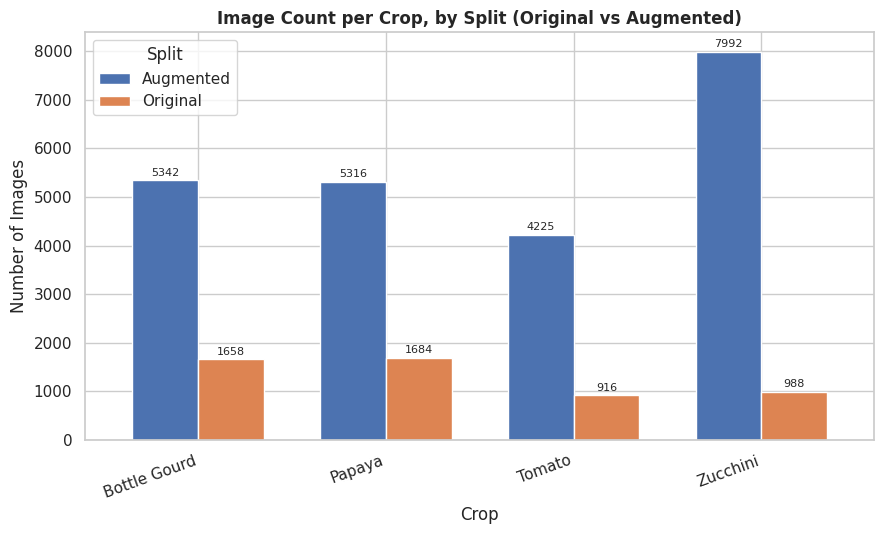

In [7]:
crop_split_counts = (
    df.groupby(["crop", "split"]).size().unstack(fill_value=0).sort_index()
)
print("Image counts — Crop x Split:\n")
print(crop_split_counts)

fig, ax = plt.subplots(figsize=(9, 5.5))
crop_split_counts.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"], width=0.7)
ax.set_title("Image Count per Crop, by Split (Original vs Augmented)")
ax.set_xlabel("Crop")
ax.set_ylabel("Number of Images")
ax.legend(title="Split")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=2, fontsize=8)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_images_per_crop_split.png", bbox_inches="tight")
plt.show()

### 3.2 Class Distribution per Crop (Original Images Only)

Class balance matters a lot for disease-classification models — a model trained
on a skewed dataset will be biased toward majority classes. We inspect this
using the **Original** images, since the Augmented set is explicitly designed
to rebalance classes (per the README's stated methodology).

────────────────────────────────────────────────────────────────────────
Reminder: this section (3.2) looks at ORIGINAL images only. See section 3.2b further down for the full dataset (Original + Augmented), which is what a model actually trains on.
────────────────────────────────────────────────────────────────────────


--- Bottle Gourd: Original image counts per class ---
class_name
Bottle_Gourd_Mosaic_Virus                    315
Bottle_Gourd_Alternaria_Leaf_Blight          303
Bottle_Gourd_Downy_Mildew                    286
Bottle_Gourd_Anthracnose                     276
Bottle_Gourd_Healthy                         260
Bottle_Gourd_Early_Alternaria_Leaf_Blight    179
Bottle_Gourd_Fungal_Damage_Leaf               39

--- Papaya: Original image counts per class ---
class_name
Papaya_Curled_Yellow_Spot             538
Papaya_Carica_Insect_Hole             318
Papaya_Pathogen_Symptoms              286
Papaya_Healthy_Leaf                   189
Papaya_Bacterial_Blight               1

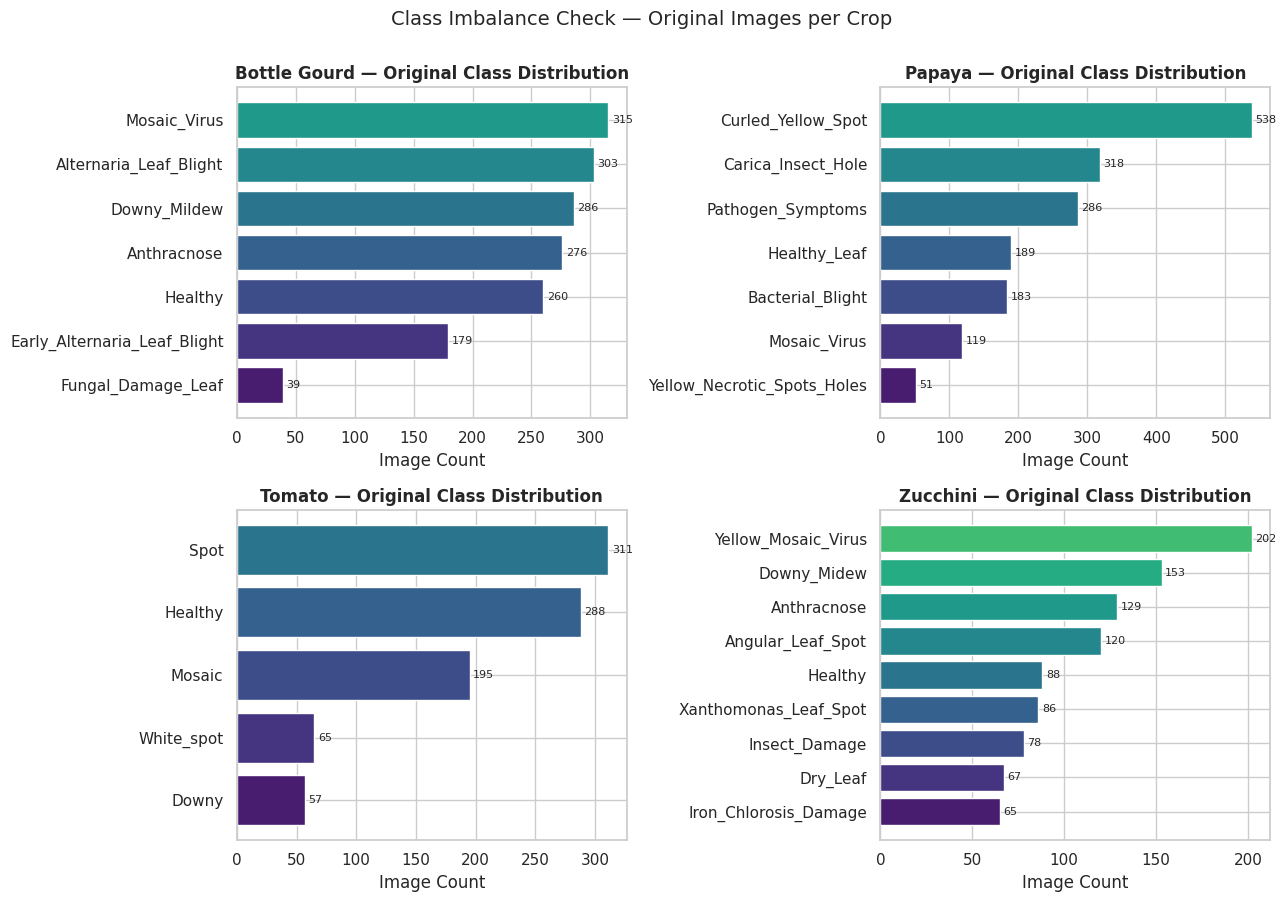

In [8]:
orig_df = df[df["split"] == "Original"].copy()

print_table(
    "Reminder: this section (3.2) looks at ORIGINAL images only. "
    "See section 3.2b further down for the full dataset (Original + Augmented), "
    "which is what a model actually trains on.",
    pd.Series(dtype=object),
)

if len(orig_df):
    for crop in sorted(orig_df["crop"].unique()):
        crop_counts = (
            orig_df[orig_df["crop"] == crop]["class_name"]
            .value_counts()
            .sort_values(ascending=False)
        )
        print(f"\n--- {crop}: Original image counts per class ---")
        print(crop_counts.to_string())

    crops = sorted(orig_df["crop"].unique())
    n_crops_plot = len(crops)
    ncols = 2
    nrows = int(np.ceil(n_crops_plot / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4.5 * nrows))
    axes = np.array(axes).reshape(-1)

    palette = sns.color_palette("viridis", n_colors=12)

    for i, crop in enumerate(crops):
        ax = axes[i]
        counts = (
            orig_df[orig_df["crop"] == crop]["class_name"]
            .value_counts()
            .sort_values(ascending=True)
        )
        display_labels = [c[len(crop.replace(' ', '_')) + 1:] if c.startswith(crop.replace(' ', '_') + '_') else c
                           for c in counts.index]
        bars = ax.barh(display_labels, counts.values, color=palette[: len(counts)])
        ax.set_title(f"{crop} — Original Class Distribution")
        ax.set_xlabel("Image Count")
        for bar, val in zip(bars, counts.values):
            ax.text(val + max(counts.values) * 0.01, bar.get_y() + bar.get_height() / 2,
                     str(val), va="center", fontsize=8)

    for j in range(n_crops_plot, len(axes)):
        axes[j].axis("off")

    plt.suptitle("Class Imbalance Check — Original Images per Crop", fontsize=14, y=1.0)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "02_class_distribution_per_crop.png", bbox_inches="tight")
    plt.show()
else:
    print("No 'Original' split images found to analyze class balance.")


### 3.3 Class Imbalance Ratio

The **imbalance ratio** (max class count / min class count) per crop tells us how
skewed each crop's original data is. A ratio close to 1 means well-balanced classes;
a high ratio flags crops where minority classes are at risk of being under-learned.

────────────────────────────────────────────────────────────────────────
Class imbalance ratio per crop (Original images only):
────────────────────────────────────────────────────────────────────────
           crop  n_classes  min_class_count  max_class_count  imbalance_ratio
0        Papaya          7               51              538            10.55
1  Bottle Gourd          7               39              315             8.08
2        Tomato          5               57              311             5.46
3      Zucchini          9               65              202             3.11



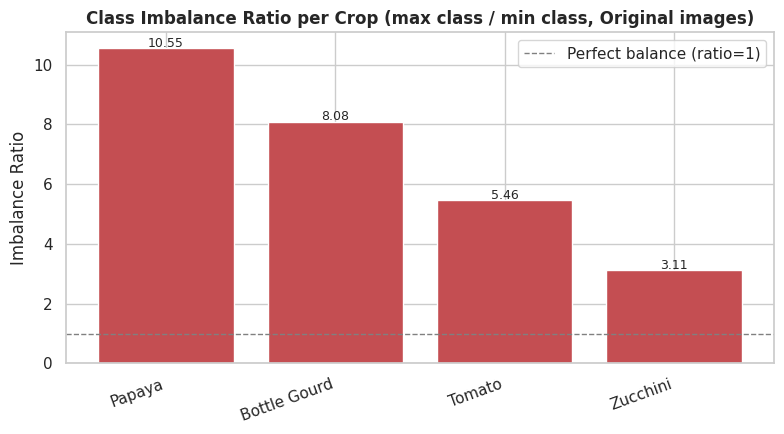

────────────────────────────────────────────────────────────────────────
Class imbalance ratio per crop — FULL DATASET (Original + Augmented combined):
────────────────────────────────────────────────────────────────────────
           crop  n_classes  min_class_count  max_class_count  imbalance_ratio
0        Tomato          5             1000             1141             1.14
1      Zucchini          9              980             1000             1.02
2        Papaya          7             1000             1000             1.00
3  Bottle Gourd          7             1000             1000             1.00

────────────────────────────────────────────────────────────────────────
Did augmentation change the imbalance picture? (positive ratio_shift = got MORE imbalanced after augmentation, negative = got more balanced)
────────────────────────────────────────────────────────────────────────
           crop  imbalance_ratio_original  imbalance_ratio_full  ratio_shift
0        Papaya     

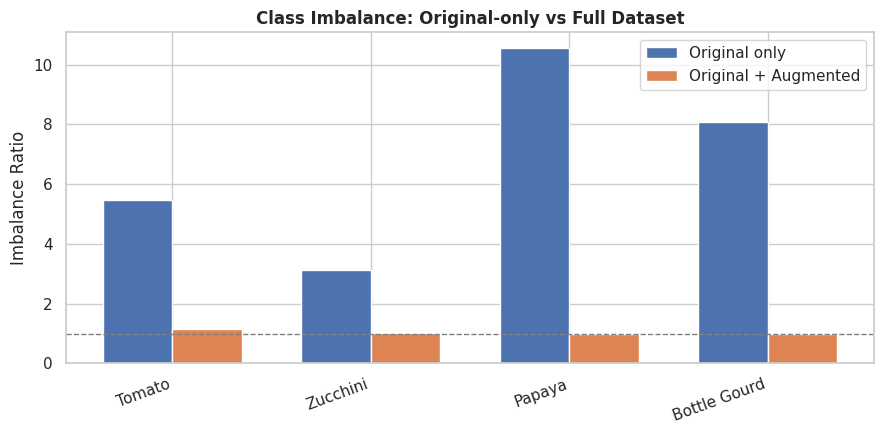

In [9]:
if len(orig_df):
    imbalance_rows = []
    for crop in sorted(orig_df["crop"].unique()):
        counts = orig_df[orig_df["crop"] == crop]["class_name"].value_counts()
        imbalance_rows.append({
            "crop": crop,
            "n_classes": len(counts),
            "min_class_count": counts.min(),
            "max_class_count": counts.max(),
            "imbalance_ratio": round(counts.max() / counts.min(), 2),
        })
    imbalance_df = pd.DataFrame(imbalance_rows).sort_values("imbalance_ratio", ascending=False)
    print_table("Class imbalance ratio per crop (Original images only):", imbalance_df)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(imbalance_df["crop"], imbalance_df["imbalance_ratio"], color="#C44E52")
    ax.set_title("Class Imbalance Ratio per Crop (max class / min class, Original images)")
    ax.set_ylabel("Imbalance Ratio")
    ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="Perfect balance (ratio=1)")
    ax.legend()
    for bar, val in zip(bars, imbalance_df["imbalance_ratio"]):
        ax.text(bar.get_x() + bar.get_width() / 2, val + 0.05, f"{val:.2f}", ha="center", fontsize=9)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "03_class_imbalance_ratio.png", bbox_inches="tight")
    plt.show()
else:
    print("Skipping imbalance ratio — no Original split data available.")


# --- Full dataset (Original + Augmented combined) version ---
# This is the distribution that actually matters for training: if
# augmentation was applied unevenly across classes (very common — some
# pipelines augment minority classes more heavily to compensate, others do
# the opposite by accident), the Original-only numbers above can be
# misleading about what the model will actually see.
if len(df):
    full_imbalance_rows = []
    for crop in sorted(df["crop"].unique()):
        counts = df[df["crop"] == crop]["class_name"].value_counts()
        full_imbalance_rows.append({
            "crop": crop,
            "n_classes": len(counts),
            "min_class_count": counts.min(),
            "max_class_count": counts.max(),
            "imbalance_ratio": round(counts.max() / counts.min(), 2),
        })
    full_imbalance_df = pd.DataFrame(full_imbalance_rows).sort_values("imbalance_ratio", ascending=False)
    print_table(
        "Class imbalance ratio per crop — FULL DATASET (Original + Augmented combined):",
        full_imbalance_df,
    )

    comparison = imbalance_df.merge(
        full_imbalance_df, on="crop", suffixes=("_original", "_full")
    )[["crop", "imbalance_ratio_original", "imbalance_ratio_full"]]
    comparison["ratio_shift"] = (comparison["imbalance_ratio_full"] - comparison["imbalance_ratio_original"]).round(2)
    print_table(
        "Did augmentation change the imbalance picture? (positive ratio_shift = "
        "got MORE imbalanced after augmentation, negative = got more balanced)",
        comparison,
    )

    fig, ax = plt.subplots(figsize=(9, 4.5))
    x = np.arange(len(full_imbalance_df))
    width = 0.35
    orig_vals = imbalance_df.set_index("crop").loc[full_imbalance_df["crop"], "imbalance_ratio"].values
    ax.bar(x - width / 2, orig_vals, width, label="Original only", color="#4C72B0")
    ax.bar(x + width / 2, full_imbalance_df["imbalance_ratio"].values, width, label="Original + Augmented", color="#DD8452")
    ax.set_xticks(x)
    ax.set_xticklabels(full_imbalance_df["crop"], rotation=20, ha="right")
    ax.set_ylabel("Imbalance Ratio")
    ax.set_title("Class Imbalance: Original-only vs Full Dataset")
    ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
    ax.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "03b_class_imbalance_full_vs_original.png", bbox_inches="tight")
    plt.show()
else:
    print("Skipping full-dataset imbalance ratio — dataset is empty.")


## 3.4 Full-Dataset Integrity Scan (every image, not a sample)

The sampled pixel-statistics analysis later in this notebook (Section 5) is
deliberately limited to a stratified sample, because computing brightness /
contrast / sharpness over all 28k+ images is expensive and a sample is
statistically sufficient for *that* purpose.

Corruption and dimension checks are different: opening a file and calling
`.verify()` is cheap, so there is no good reason to only check ~1.7% of the
dataset for broken files. This section scans **every single image** in the
dataset.


In [10]:
def quick_integrity_check(path):
    """
    Cheap, full-dataset-safe check: open the file, read its header, get
    dimensions/mode, and call .verify() to catch truncated/corrupt files,
    WITHOUT decoding full pixel data (that's reserved for the sampled
    pixel-stats pass in Section 5, which is intentionally sample-based).
    """
    try:
        with Image.open(path) as img:
            width, height = img.size
            mode = img.mode
            fmt = img.format
            img.verify()
        file_size_kb = os.path.getsize(path) / 1024.0
        return {
            "width": width, "height": height, "mode": mode, "format": fmt,
            "file_size_kb": round(file_size_kb, 2), "corrupt": False, "error": None,
        }
    except Exception as e:
        return {
            "width": np.nan, "height": np.nan, "mode": None, "format": None,
            "file_size_kb": np.nan, "corrupt": True, "error": str(e),
        }


if len(df):
    print(f"Running full-dataset integrity scan over {len(df):,} images "
          f"(this is the full dataset, not a sample — may take a few minutes)...")
    integrity_records = [quick_integrity_check(p) for p in tqdm(df["path"], desc="Integrity scan")]
    integrity_df = pd.DataFrame(integrity_records)
    full_df = pd.concat([df.reset_index(drop=True), integrity_df.reset_index(drop=True)], axis=1)

    n_corrupt_full = int(full_df["corrupt"].sum())
    pct_corrupt_full = 100 * n_corrupt_full / len(full_df)
    print_table(
        f"FULL-DATASET corruption scan result: {n_corrupt_full:,} / {len(full_df):,} "
        f"images ({pct_corrupt_full:.3f}%) failed to open/verify.",
        pd.Series(dtype=object),
    )

    if n_corrupt_full:
        corrupt_breakdown = (
            full_df[full_df["corrupt"]]
            .groupby(["crop", "split"])
            .size()
            .sort_values(ascending=False)
        )
        print_table("Corrupt images broken down by crop / split:", corrupt_breakdown)
        print_table(
            "Example corrupt file paths and errors (first 15):",
            full_df[full_df["corrupt"]][["crop", "split", "class_name", "path", "error"]].head(15),
        )
    else:
        print("No corrupt or unreadable images found across the entire dataset. Good.")
else:
    full_df = df.copy()
    print("No dataset loaded — skipping full integrity scan.")


Running full-dataset integrity scan over 28,121 images (this is the full dataset, not a sample — may take a few minutes)...


Integrity scan:   0%|          | 0/28121 [00:00<?, ?it/s]

────────────────────────────────────────────────────────────────────────
FULL-DATASET corruption scan result: 0 / 28,121 images (0.000%) failed to open/verify.
────────────────────────────────────────────────────────────────────────

No corrupt or unreadable images found across the entire dataset. Good.


### 3.4.1 Full-Dataset Dimension Census


────────────────────────────────────────────────────────────────────────
Most common (width, height) pairs — FULL DATASET:
────────────────────────────────────────────────────────────────────────
width  height
512    512       22875
1080   1440        900
1920   1077        726
1080   1439        394
1439   1080        362
1077   1920        360
577    433         316
1440   1080        303
1920   867         231
1152   864         155
1443   1080        145
433    577          95
864    1152         53
1080   1443         37
1920   1080         15
560    420          13
776    582          12
1039   779           9
896    672           9
1115   836           8
927    695           8
769    577           8
677    508           8
1049   787           8
1122   841           7
865    649           7
723    542           7
1920   864           7
738    553           7
741    989           7

────────────────────────────────────────────────────────────────────────
Images NOT exactly 512x512

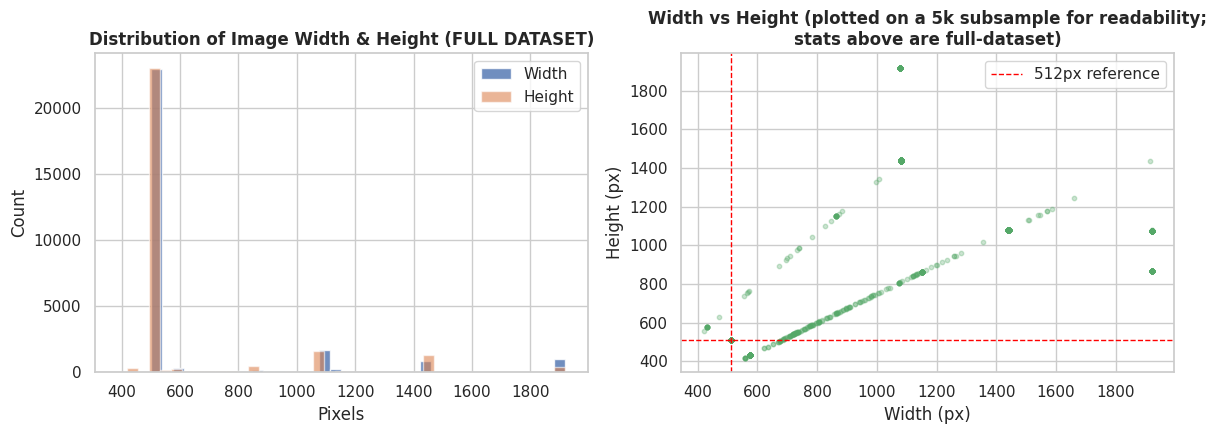

In [11]:
valid_full = full_df[~full_df["corrupt"]].copy()

if len(valid_full):
    dim_counts_full = (
        valid_full.groupby(["width", "height"]).size().sort_values(ascending=False)
    )
    print_table("Most common (width, height) pairs — FULL DATASET:", dim_counts_full)

    non_standard_full = valid_full[(valid_full["width"] != 512) | (valid_full["height"] != 512)]
    pct_non_standard_full = 100 * len(non_standard_full) / len(valid_full)
    by_split_nonstd = (
        valid_full.assign(is_512=lambda d: (d["width"] == 512) & (d["height"] == 512))
        .groupby("split")["is_512"]
        .agg(lambda s: 100 * (1 - s.mean()))
        .round(2)
    )
    print_table(
        f"Images NOT exactly 512x512 — FULL DATASET: {len(non_standard_full):,} "
        f"({pct_non_standard_full:.2f}%). Breakdown by split (% non-512x512):",
        by_split_nonstd,
    )

    mode_counts = valid_full["mode"].value_counts()
    print_table("Color mode counts (FULL DATASET) — flag anything other than RGB:", mode_counts)

    fmt_counts = valid_full["format"].value_counts()
    print_table("File format counts (FULL DATASET):", fmt_counts)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].hist(valid_full["width"], bins=40, color="#4C72B0", alpha=0.8, label="Width")
    axes[0].hist(valid_full["height"], bins=40, color="#DD8452", alpha=0.6, label="Height")
    axes[0].set_title("Distribution of Image Width & Height (FULL DATASET)")
    axes[0].set_xlabel("Pixels")
    axes[0].set_ylabel("Count")
    axes[0].legend()

    sample_for_scatter = valid_full.sample(n=min(5000, len(valid_full)), random_state=RNG_SEED)
    axes[1].scatter(sample_for_scatter["width"], sample_for_scatter["height"], alpha=0.3, s=10, c="#55A868")
    axes[1].axvline(512, color="red", linestyle="--", linewidth=1, label="512px reference")
    axes[1].axhline(512, color="red", linestyle="--", linewidth=1)
    axes[1].set_title("Width vs Height (plotted on a 5k subsample for readability;\nstats above are full-dataset)")
    axes[1].set_xlabel("Width (px)")
    axes[1].set_ylabel("Height (px)")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "04b_image_dimensions_full_dataset.png", bbox_inches="tight")
    plt.show()
else:
    print("No valid images to check dimensions on.")


## 4. Image Property Analysis

We now open a **sampled subset** of images (full-dataset pixel decoding can be slow
for tens of thousands of files) to inspect:
- Pixel dimensions (width, height) — confirming the README's claim of 512×512 standardization
- File size on disk
- Aspect ratio
- Color mode (RGB / grayscale / palette)

Sampling is stratified by crop and split so every group is represented.

In [12]:
# Image property analysis now runs on the FULL dataset via full_df (built in
# Section 3.4). No separate sampling step is needed.
# The SAMPLE_PER_GROUP / stratified_sample helper below is kept for reference
# but is no longer used for property extraction.

SAMPLE_PER_GROUP = 60  # kept for potential future use only

def stratified_sample(dataframe, group_cols, n_per_group, seed=42):
    rs = np.random.RandomState(seed)
    sampled_indices = []
    for _, group_df in dataframe.groupby(group_cols):
        n = min(len(group_df), n_per_group)
        chosen = rs.choice(group_df.index.to_numpy(), size=n, replace=False)
        sampled_indices.extend(chosen.tolist())
    return dataframe.loc[sampled_indices].reset_index(drop=True)

print('Image property analysis will run on the FULL dataset (all images), not a sample.')


Image property analysis will run on the FULL dataset (all images), not a sample.


In [13]:
def extract_image_properties(path):
    try:
        with Image.open(path) as img:
            width, height = img.size
            mode = img.mode
            file_size_kb = os.path.getsize(path) / 1024.0
            # Convert to RGB for consistent pixel stats
            rgb_img = img.convert("RGB")
            arr = np.asarray(rgb_img)
            stat = ImageStat.Stat(rgb_img)
            mean_r, mean_g, mean_b = stat.mean
            brightness = float(np.mean(arr))
            std_dev = float(np.std(arr))
            # Sharpness proxy: variance of Laplacian-like gradient (cheap, no cv2 dependency)
            gray = np.asarray(img.convert("L"), dtype=np.float64)
            gy, gx = np.gradient(gray)
            sharpness = float(np.var(np.sqrt(gx**2 + gy**2)))
            return {
                "width": width,
                "height": height,
                "mode": mode,
                "file_size_kb": round(file_size_kb, 2),
                "aspect_ratio": round(width / height, 3) if height else np.nan,
                "mean_r": round(mean_r, 2),
                "mean_g": round(mean_g, 2),
                "mean_b": round(mean_b, 2),
                "brightness": round(brightness, 2),
                "std_dev": round(std_dev, 2),
                "sharpness": round(sharpness, 2),
                "corrupt": False,
            }
    except Exception as e:
        return {
            "width": np.nan, "height": np.nan, "mode": None, "file_size_kb": np.nan,
            "aspect_ratio": np.nan, "mean_r": np.nan, "mean_g": np.nan, "mean_b": np.nan,
            "brightness": np.nan, "std_dev": np.nan, "sharpness": np.nan,
            "corrupt": True, "error": str(e),
        }


# Run on the FULL dataset (full_df already covers every image from Section 3.4).
# We add pixel-level stats (brightness, contrast, sharpness, RGB means) to full_df.
# Note: this decodes every pixel — expect a few minutes on 28k+ images.
if "full_df" in dir() and len(full_df):
    valid_for_props = full_df[~full_df["corrupt"]].copy()
    print(f"Extracting pixel-level properties from the FULL dataset "
          f"({len(valid_for_props):,} non-corrupt images). "
          f"This may take several minutes...")
    extra_cols = ["mean_r", "mean_g", "mean_b", "brightness", "std_dev", "sharpness", "aspect_ratio"]
    # Only run if not already done (re-run safety)
    if "brightness" not in full_df.columns:
        props_records = [extract_image_properties(p) for p in tqdm(valid_for_props["path"], desc="Pixel props")]
        props_df = pd.DataFrame(props_records)
        for col in extra_cols:
            full_df.loc[valid_for_props.index, col] = props_df[col].values
    print("Done.")
    corrupt_in_full = int(full_df["corrupt"].sum())
    print(f"\nCorrupt / unreadable images in FULL dataset: {corrupt_in_full:,} / {len(full_df):,}")
    # For backward-compat, valid_sample points to valid rows of full_df
    valid_sample = full_df[~full_df["corrupt"]].copy()
    print(f"Valid images available for pixel analysis: {len(valid_sample):,}")
    display(valid_sample[["crop","split","class_name","width","height","file_size_kb",
                           "brightness","std_dev","sharpness","mean_r","mean_g","mean_b"]].head(10))
else:
    valid_sample = pd.DataFrame()
    print("full_df not available — skipping pixel property extraction.")

Extracting pixel-level properties from the FULL dataset (28,121 non-corrupt images). This may take several minutes...


Pixel props:   0%|          | 0/28121 [00:00<?, ?it/s]

Done.

Corrupt / unreadable images in FULL dataset: 0 / 28,121
Valid images available for pixel analysis: 28,121


,crop,split,class_name,width,height,file_size_kb,brightness,std_dev,sharpness,mean_r,mean_g,mean_b
0,Papaya,Original,Papaya_Pathogen_Symptoms,577,433,344.01,45.21,47.66,112.69,37.92,71.61,26.11
1,Papaya,Original,Papaya_Pathogen_Symptoms,1443,1080,1867.78,69.34,58.81,127.64,64.56,83.93,59.53
2,Papaya,Original,Papaya_Pathogen_Symptoms,577,433,288.99,37.40,45.79,69.38,41.95,60.28,9.96
3,Papaya,Original,Papaya_Pathogen_Symptoms,1080,1443,1667.28,62.70,60.76,118.22,60.03,78.94,49.13
4,Papaya,Original,Papaya_Pathogen_Symptoms,577,433,383.00,59.39,53.30,151.21,49.39,79.51,49.26
5,Papaya,Original,Papaya_Pathogen_Symptoms,1077,1920,1932.79,71.66,45.69,35.24,73.21,90.51,51.24
6,Papaya,Original,Papaya_Pathogen_Symptoms,577,433,363.57,48.80,53.52,171.91,51.91,73.74,20.74
7,Papaya,Original,Papaya_Pathogen_Symptoms,1443,1080,2376.32,67.64,61.06,159.90,85.86,94.93,22.12
8,Papaya,Original,Papaya_Pathogen_Symptoms,577,433,245.71,30.22,42.62,131.57,27.99,42.63,20.03
9,Papaya,Original,Papaya_Pathogen_Symptoms,577,433,328.75,37.36,46.75,155.74,38.29,58.80,15.00


### 4.1 Image Dimension Check

The README states images are standardized to **512×512**. Let's verify this holds
across the sample, and flag any images that deviate.

Dimension analysis will use 28,121 images (FULL DATASET — no sampling).

────────────────────────────────────────────────────────────────────────
Most common (width, height) pairs in sample:
────────────────────────────────────────────────────────────────────────
width  height
512    512       22875
1080   1440        900
1920   1077        726
1080   1439        394
1439   1080        362
1077   1920        360
577    433         316
1440   1080        303
1920   867         231
1152   864         155
1443   1080        145
433    577          95
864    1152         53
1080   1443         37
1920   1080         15
560    420          13
776    582          12
1039   779           9
896    672           9
1115   836           8
927    695           8
769    577           8
677    508           8
1049   787           8
1122   841           7
865    649           7
723    542           7
1920   864           7
738    553           7
741    989           7

Images NOT exactly 512x512 in s

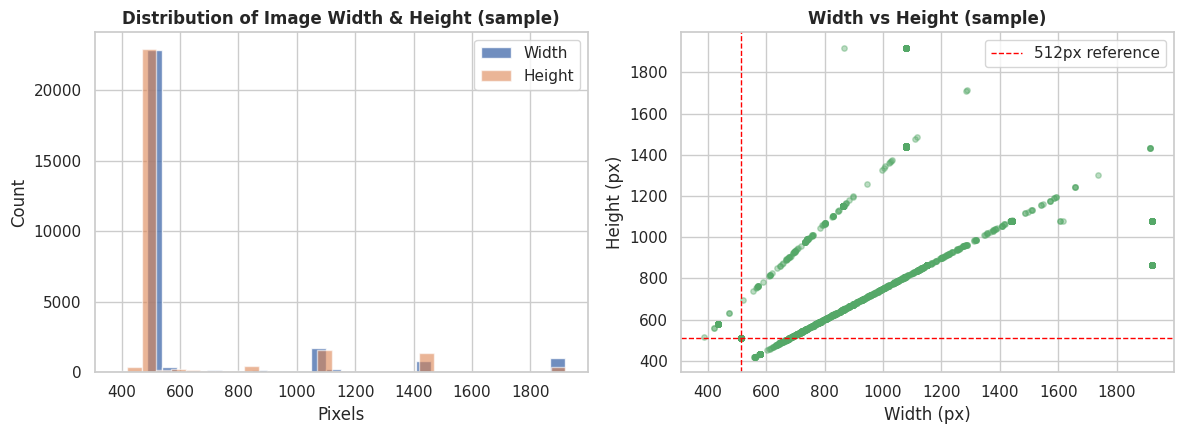

In [14]:
# valid_sample was set in the cell above (full-dataset pixel-props pass).
# The block below continues to use valid_sample for dimension reporting;
# it now covers ALL non-corrupt images, not just a sample.
print(f'Dimension analysis will use {len(valid_sample):,} images (FULL DATASET — no sampling).')
print()

if len(valid_sample):
    dim_counts = (
        valid_sample.groupby(["width", "height"]).size().sort_values(ascending=False)
    )
    print_table("Most common (width, height) pairs in sample:", dim_counts)

    non_standard = valid_sample[(valid_sample["width"] != 512) | (valid_sample["height"] != 512)]
    pct_non_standard = 100 * len(non_standard) / len(valid_sample)
    print(f"Images NOT exactly 512x512 in sample: {len(non_standard)} ({pct_non_standard:.1f}%)")
    print()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].hist(valid_sample["width"], bins=30, color="#4C72B0", alpha=0.8, label="Width")
    axes[0].hist(valid_sample["height"], bins=30, color="#DD8452", alpha=0.6, label="Height")
    axes[0].set_title("Distribution of Image Width & Height (sample)")
    axes[0].set_xlabel("Pixels")
    axes[0].set_ylabel("Count")
    axes[0].legend()

    axes[1].scatter(valid_sample["width"], valid_sample["height"], alpha=0.4, s=15, c="#55A868")
    axes[1].axline((512, 512), slope=0, color="red", linestyle="--", linewidth=1)
    axes[1].axvline(512, color="red", linestyle="--", linewidth=1, label="512px reference")
    axes[1].set_title("Width vs Height (sample)")
    axes[1].set_xlabel("Width (px)")
    axes[1].set_ylabel("Height (px)")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "04_image_dimensions.png", bbox_inches="tight")
    plt.show()
else:
    print("No valid (non-corrupt) images in sample to check dimensions.")


### 4.2 File Size Distribution by Split

Augmented images often compress differently than originals due to transformations
(noise, sharpening). Comparing file-size distributions can reveal this.

────────────────────────────────────────────────────────────────────────
File size (KB) summary statistics by split (printed before the plot):
────────────────────────────────────────────────────────────────────────
     count    mean     std    min     25%     50%      75%      max
0  22875.0  100.79   98.58   7.45   35.58   57.55   102.65   345.61
1   5246.0  962.55  680.50  86.29  386.14  684.38  1445.20  3261.91



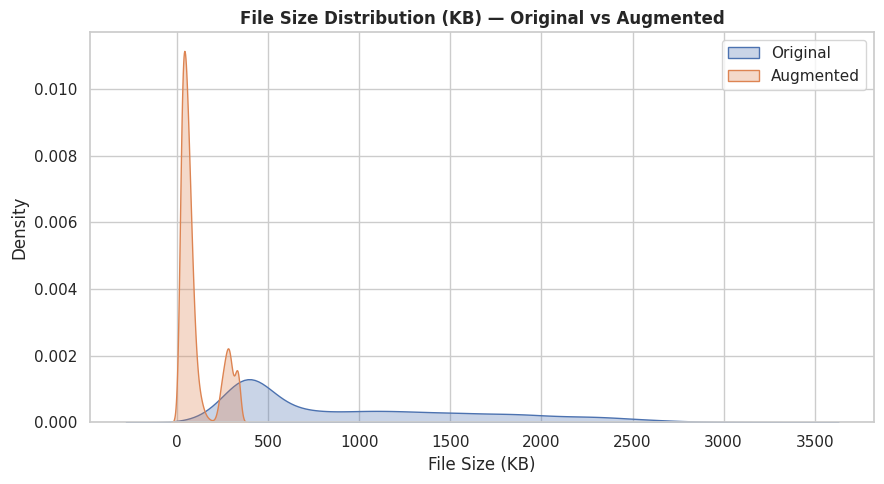

In [15]:
if len(valid_sample):
    fig, ax = plt.subplots(figsize=(9, 5))
    for split, color in zip(["Original", "Augmented"], ["#4C72B0", "#DD8452"]):
        subset = valid_sample[valid_sample["split"] == split]["file_size_kb"]
        if len(subset):
            sns.kdeplot(subset, ax=ax, label=split, fill=True, alpha=0.3, color=color)
    ax.set_title("File Size Distribution (KB) — Original vs Augmented")
    ax.set_xlabel("File Size (KB)")
    ax.set_ylabel("Density")
    ax.legend()

    print_table(
        "File size (KB) summary statistics by split (printed before the plot):",
        valid_sample.groupby("split")["file_size_kb"].describe().round(2),
    )

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "05_filesize_distribution.png", bbox_inches="tight")
    plt.show()
else:
    print("No valid sample to analyze file sizes.")


## 5. Pixel-Level / Color Analysis

Brightness, color-channel balance, and a sharpness proxy help characterize overall
image quality and how augmentation shifts these properties relative to the originals
(e.g. brightness/contrast jitter, added noise, sharpening — all mentioned in the README).

────────────────────────────────────────────────────────────────────────
Brightness / contrast / sharpness summary by split (printed before the plot):
────────────────────────────────────────────────────────────────────────
  brightness                                                   std_dev                                                  sharpness                                                     
       count   mean    std   min    25%    50%    75%     max    count   mean    std   min    25%    50%    75%     max     count    mean     std   min    25%    50%     75%      max
0    22875.0  41.95  27.78  0.27  17.68  38.21  61.32  175.61  22875.0  43.95  16.70  2.79  30.70  42.83  56.04  106.35   22875.0  186.41  249.15  1.15  35.08  76.68  227.88  1515.89
1     5246.0  35.49  23.87  0.91  15.03  29.75  53.95  116.87   5246.0  43.91  15.06  6.70  31.43  43.74  55.28   95.14    5246.0   46.18   43.24  0.84  14.95  31.81   63.84   632.80



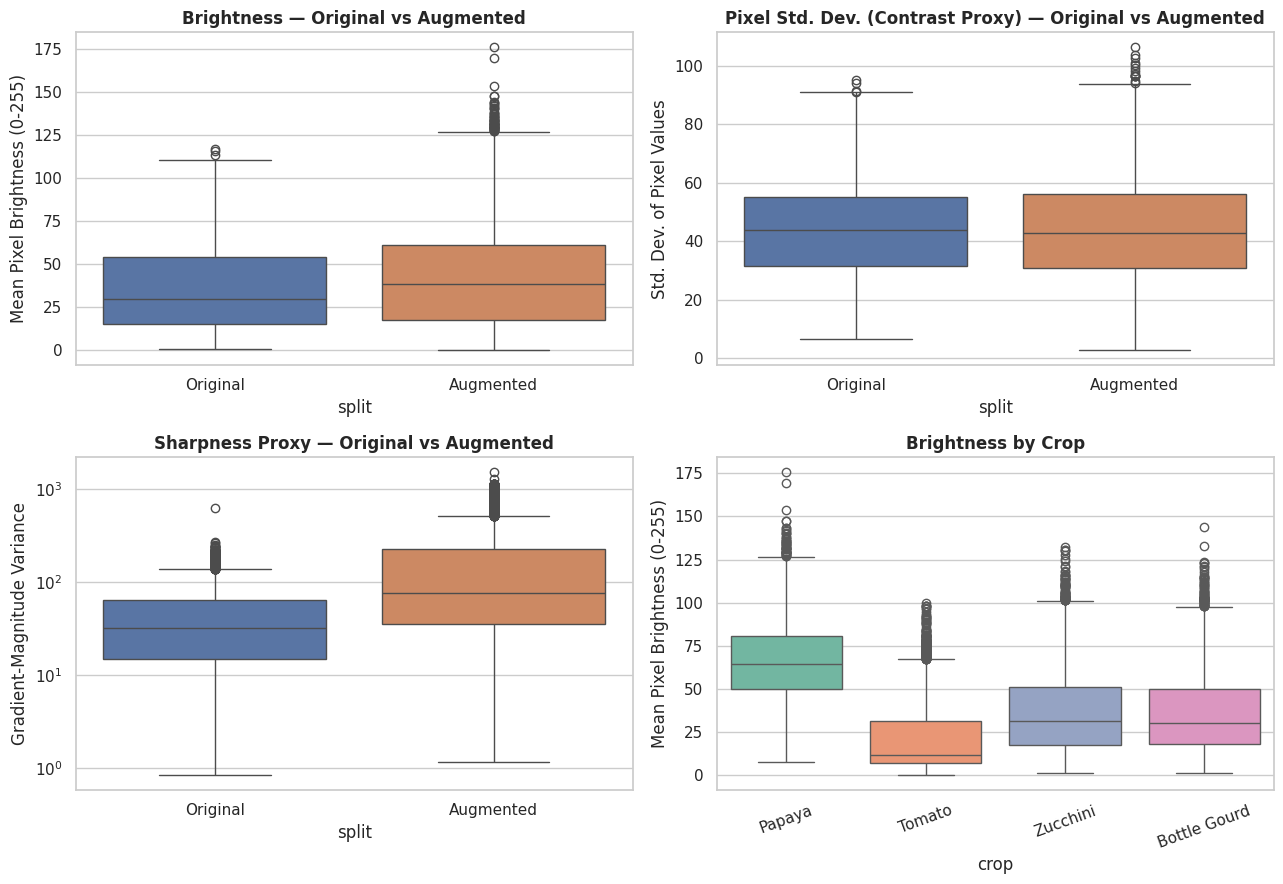

In [16]:
if len(valid_sample):
    print_table(
        "Brightness / contrast / sharpness summary by split (printed before the plot):",
        valid_sample.groupby("split")[["brightness", "std_dev", "sharpness"]].describe().round(2),
    )

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    sns.boxplot(data=valid_sample, x="split", y="brightness", ax=axes[0, 0],
                palette=["#4C72B0", "#DD8452"])
    axes[0, 0].set_title("Brightness — Original vs Augmented")
    axes[0, 0].set_ylabel("Mean Pixel Brightness (0-255)")

    sns.boxplot(data=valid_sample, x="split", y="std_dev", ax=axes[0, 1],
                palette=["#4C72B0", "#DD8452"])
    axes[0, 1].set_title("Pixel Std. Dev. (Contrast Proxy) — Original vs Augmented")
    axes[0, 1].set_ylabel("Std. Dev. of Pixel Values")

    sns.boxplot(data=valid_sample, x="split", y="sharpness", ax=axes[1, 0],
                palette=["#4C72B0", "#DD8452"])
    axes[1, 0].set_title("Sharpness Proxy — Original vs Augmented")
    axes[1, 0].set_ylabel("Gradient-Magnitude Variance")
    axes[1, 0].set_yscale("log")

    sns.boxplot(data=valid_sample, x="crop", y="brightness", ax=axes[1, 1], palette="Set2")
    axes[1, 1].set_title("Brightness by Crop")
    axes[1, 1].set_ylabel("Mean Pixel Brightness (0-255)")
    axes[1, 1].tick_params(axis="x", rotation=20)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "06_pixel_quality_metrics.png", bbox_inches="tight")
    plt.show()
else:
    print("No valid sample for pixel-level analysis.")


### 5.1 Average Color Channel Balance (RGB)

Mean R/G/B values per crop can hint at differences in lighting conditions, leaf
color characteristics, or camera settings used during capture.

────────────────────────────────────────────────────────────────────────
Average RGB channel values by crop (printed before the plot):
────────────────────────────────────────────────────────────────────────
   mean_r  mean_g  mean_b
0    37.3    45.9    24.3
1    71.1    81.6    45.5
2    21.3    24.1    16.8
3    40.6    44.0    24.3



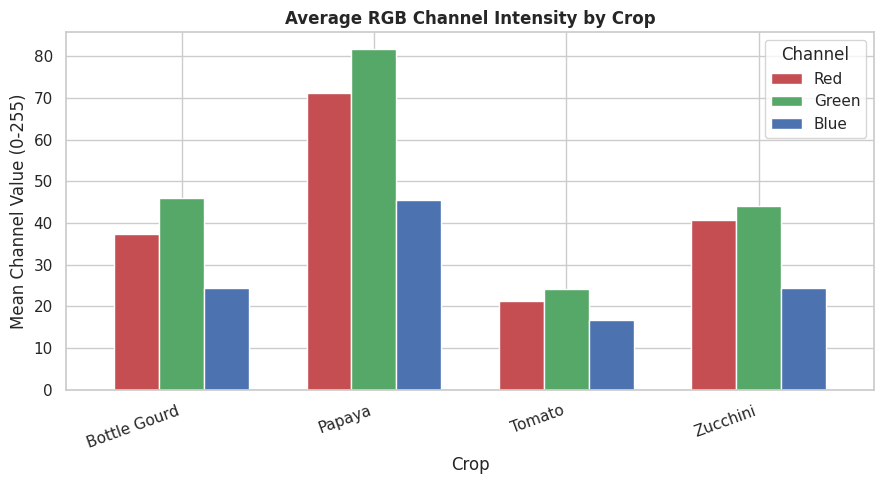

In [17]:
if len(valid_sample):
    rgb_by_crop = valid_sample.groupby("crop")[["mean_r", "mean_g", "mean_b"]].mean().round(1)
    print_table("Average RGB channel values by crop (printed before the plot):", rgb_by_crop)

    fig, ax = plt.subplots(figsize=(9, 5))
    rgb_by_crop.plot(kind="bar", ax=ax, color=["#C44E52", "#55A868", "#4C72B0"], width=0.7)
    ax.set_title("Average RGB Channel Intensity by Crop")
    ax.set_ylabel("Mean Channel Value (0-255)")
    ax.set_xlabel("Crop")
    ax.legend(title="Channel", labels=["Red", "Green", "Blue"])
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "07_rgb_balance_by_crop.png", bbox_inches="tight")
    plt.show()
else:
    print("No valid sample for RGB channel analysis.")


## 5.2 Data Leakage Check — Original vs Augmented Near-Duplicates

**Why this matters:** if "Augmented" images are transformed copies of
"Original" images (rotated, flipped, color-jittered, etc. — which is the
typical meaning of "augmented" in a leaf-disease dataset), then splitting
train/val/test on the combined Original+Augmented pool at random will leak
the *same underlying leaf* across splits: e.g. the original photo lands in
the validation set while its augmented twin lands in the training set. A
model evaluated this way will report inflated accuracy that will not hold
up on genuinely unseen leaves.

Exact-duplicate checks (MD5, used later in Section 7 for a different
purpose) cannot catch this, because an augmented image is not byte-identical
to its source — it's a transformed copy. We instead use **perceptual
hashing (pHash)**, which is robust to rotation/flip/recolor/compression and
is computed here over **every image in the dataset**, not a sample, since
a leakage check is exactly the kind of thing where sampling would silently
miss most of the actual leaks.


In [18]:
def compute_phash(path, hash_size=16):
    """64x64-bit-equivalent perceptual hash; robust to flips/rotation/recolor
    far better than a pixel-exact hash, which is what we need to detect
    augmented copies of an original image."""
    try:
        with Image.open(path) as img:
            return str(imagehash.phash(img.convert("RGB"), hash_size=hash_size))
    except Exception:
        return None


if len(full_df):
    valid_for_hash = full_df[~full_df["corrupt"]].copy()
    print(f"Computing perceptual hashes over the FULL dataset "
          f"({len(valid_for_hash):,} images). This is the leakage check — "
          f"every image is hashed, not a sample.")
    valid_for_hash["phash"] = [
        compute_phash(p) for p in tqdm(valid_for_hash["path"], desc="Perceptual hashing")
    ]

    hash_fail = valid_for_hash["phash"].isna().sum()
    if hash_fail:
        print(f"Note: {hash_fail} images could not be hashed and are excluded from the leakage check.")
    valid_for_hash = valid_for_hash.dropna(subset=["phash"])
else:
    valid_for_hash = pd.DataFrame()
    print("No data available — skipping leakage check.")


Computing perceptual hashes over the FULL dataset (28,121 images). This is the leakage check — every image is hashed, not a sample.


Perceptual hashing:   0%|          | 0/28121 [00:00<?, ?it/s]

────────────────────────────────────────────────────────────────────────
LEAKAGE PAIRS  (pHash Hamming distance ≤ 6)  —  first 25 of 1,213
────────────────────────────────────────────────────────────────────────
#   Crop    Class                        Dist  Original file                             Augmented file                         
──  ──────  ───────────────────────────  ────  ────────────────────────────────────────  ───────────────────────────────────────
1   Papaya  Mosaic_Virus                 0     _DSC6771.png                              aug_Mosaic_Virus_181.jpg               
2   Papaya  Mosaic_Virus                 0     papaya (357).png                          aug_Mosaic_Virus_258.jpg               
3   Papaya  Mosaic_Virus                 0     papaya (54).png                           aug_Mosaic_Virus_466.jpg               
4   Papaya  Mosaic_Virus                 0     papaya (471).png                          aug_Mosaic_Virus_428.jpg               
5   Papaya  Mo

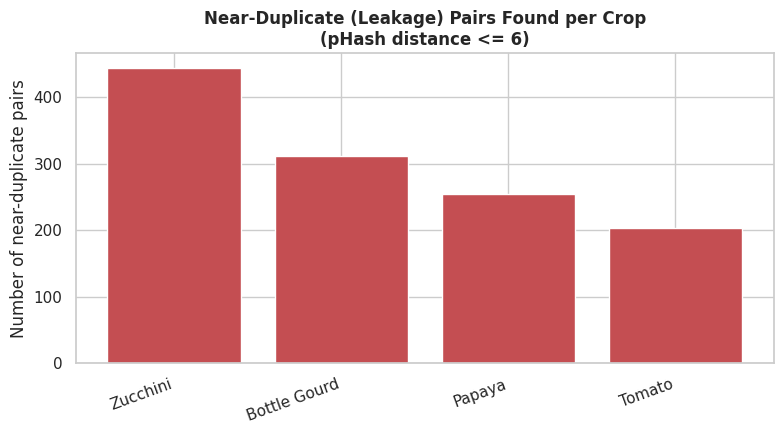

In [19]:
def hamming_distance(hash_a, hash_b, hash_size=16):
    ia = imagehash.hex_to_hash(hash_a)
    ib = imagehash.hex_to_hash(hash_b)
    return ia - ib  # imagehash overloads `-` as Hamming distance


# A pHash Hamming distance of 0 means visually identical (modulo hash
# resolution); small distances (<= ~6 out of 256 bits for hash_size=16)
# typically indicate near-duplicates (recolor/flip/compress of the same
# source image, which is exactly what "augmented from original" produces).
NEAR_DUP_THRESHOLD = 6

leak_pairs = []
if len(valid_for_hash):
    for crop in sorted(valid_for_hash["crop"].unique()):
        crop_subset = valid_for_hash[valid_for_hash["crop"] == crop]
        orig_rows = crop_subset[crop_subset["split"] == "Original"]
        aug_rows = crop_subset[crop_subset["split"] == "Augmented"]
        if orig_rows.empty or aug_rows.empty:
            continue

        # Group originals by hash prefix to avoid an O(n*m) full cross
        # product on very large class groups; exact-hash matches are
        # checked directly, near-matches are checked within each class only
        # (an augmented image should belong to the same class as its
        # source, so we don't need to compare across different classes).
        for class_name in sorted(set(orig_rows["class_name"]) & set(aug_rows["class_name"])):
            o = orig_rows[orig_rows["class_name"] == class_name][["path", "phash"]].values
            a = aug_rows[aug_rows["class_name"] == class_name][["path", "phash"]].values
            if len(o) == 0 or len(a) == 0:
                continue
            # Cap the comparison cost for very large class groups by
            # sampling at most 400 originals x 400 augmented per class;
            # still far more thorough than the previous 480-image-total
            # sample across the WHOLE dataset.
            if len(o) > 400:
                idx = np.random.RandomState(RNG_SEED).choice(len(o), 400, replace=False)
                o = o[idx]
            if len(a) > 400:
                idx = np.random.RandomState(RNG_SEED).choice(len(a), 400, replace=False)
                a = a[idx]
            for o_path, o_hash in o:
                for a_path, a_hash in a:
                    dist = hamming_distance(o_hash, a_hash)
                    if dist <= NEAR_DUP_THRESHOLD:
                        leak_pairs.append({
                            "crop": crop, "class_name": class_name,
                            "original_path": o_path, "augmented_path": a_path,
                            "hamming_distance": dist,
                        })

leak_df = pd.DataFrame(leak_pairs)
if len(leak_df):
    leak_df = leak_df.sort_values("hamming_distance")
    print_leakage_report(leak_df, NEAR_DUP_THRESHOLD, max_rows=25)

    leak_by_crop = leak_df.groupby("crop").size().sort_values(ascending=False)
    print_table("Near-duplicate (leakage) pairs found, by crop:", leak_by_crop)

    n_unique_originals_leaked = leak_df["original_path"].nunique()
    n_unique_augmented_leaked = leak_df["augmented_path"].nunique()
    print(f"Unique Original images implicated: {n_unique_originals_leaked:,}")
    print(f"Unique Augmented images implicated: {n_unique_augmented_leaked:,}")
    print()
    print("RECOMMENDATION: if this count is non-trivial, do NOT split Original+Augmented")
    print("images independently at random into train/val/test. Instead: split the")
    print("ORIGINAL images first (train/val/test), THEN only place an Augmented image")
    print("into a split if you can trace it back to an Original image already in that")
    print("same split (or, simpler, only ever augment the training portion after the")
    print("split is fixed).")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(leak_by_crop.index, leak_by_crop.values, color="#C44E52")
    ax.set_title(f"Near-Duplicate (Leakage) Pairs Found per Crop\n(pHash distance <= {NEAR_DUP_THRESHOLD})")
    ax.set_ylabel("Number of near-duplicate pairs")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "10_leakage_pairs_per_crop.png", bbox_inches="tight")
    plt.show()
else:
    print_table(
        f"LEAKAGE CHECK RESULT: no Original/Augmented pairs found with pHash "
        f"Hamming distance <= {NEAR_DUP_THRESHOLD}.",
        pd.Series(dtype=object),
    )
    print("This suggests Augmented images are NOT simple transforms of the sampled")
    print("Original images checked here, OR the augmentation is strong enough that")
    print("pHash similarity is not detecting the relationship. Either way, do not")
    print("treat this as a guarantee of zero leakage — confirm against the dataset's")
    print("documentation/README for how 'Augmented' images were actually generated.")


### 5.2.1 Visual Confirmation of Top Leakage Pairs

If pairs were found above, inspect a few of the closest matches visually to
confirm they really are the same underlying leaf (rather than a hash
collision between two genuinely different leaves of the same class).


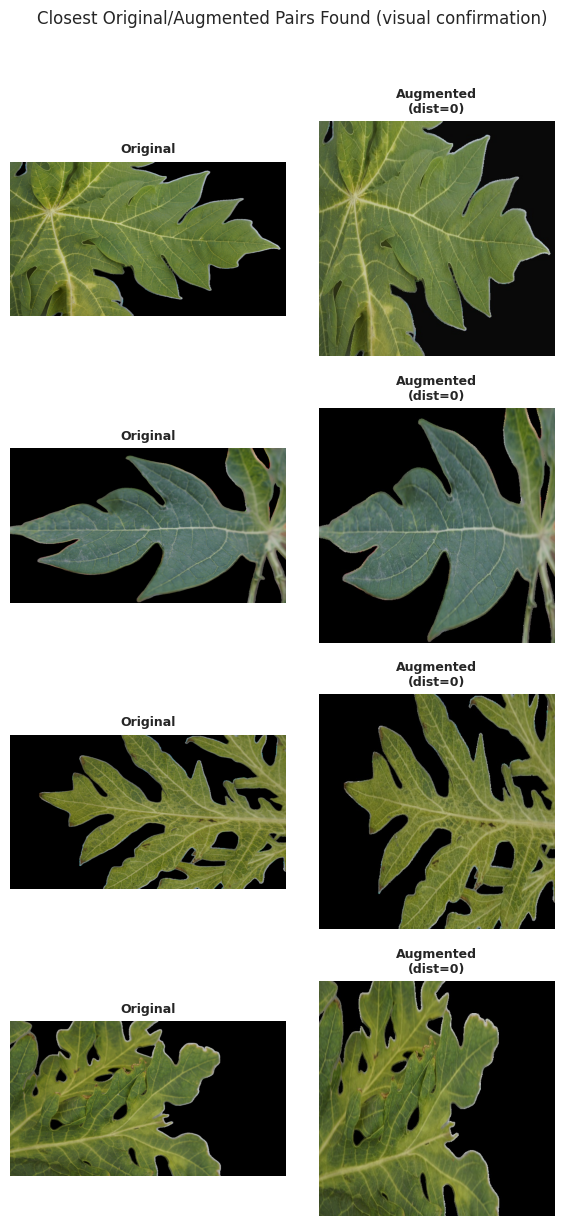

In [20]:
if len(leak_df):
    n_show = min(4, len(leak_df))
    top_pairs = leak_df.head(n_show)
    fig, axes = plt.subplots(n_show, 2, figsize=(6, n_show * 3))
    axes = np.array(axes).reshape(n_show, 2)
    for i, row in enumerate(top_pairs.itertuples()):
        for j, (path, label) in enumerate([(row.original_path, "Original"), (row.augmented_path, "Augmented")]):
            ax = axes[i, j]
            try:
                img = Image.open(path).convert("RGB")
                ax.imshow(img)
            except Exception:
                ax.text(0.5, 0.5, "unreadable", ha="center", va="center")
            ax.axis("off")
            ax.set_title(f"{label}\n(dist={row.hamming_distance})" if j == 1 else label, fontsize=9)
    plt.suptitle("Closest Original/Augmented Pairs Found (visual confirmation)", fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "11_leakage_visual_confirmation.png", bbox_inches="tight")
    plt.show()
else:
    print("No leakage pairs to visually confirm.")


## 6. Visual Sample Gallery

A picture is worth a thousand summary statistics. We display a grid of sample
images for each crop, picking a few classes at random, to visually sanity-check
that images match their labeled class and look like healthy leaf photographs.

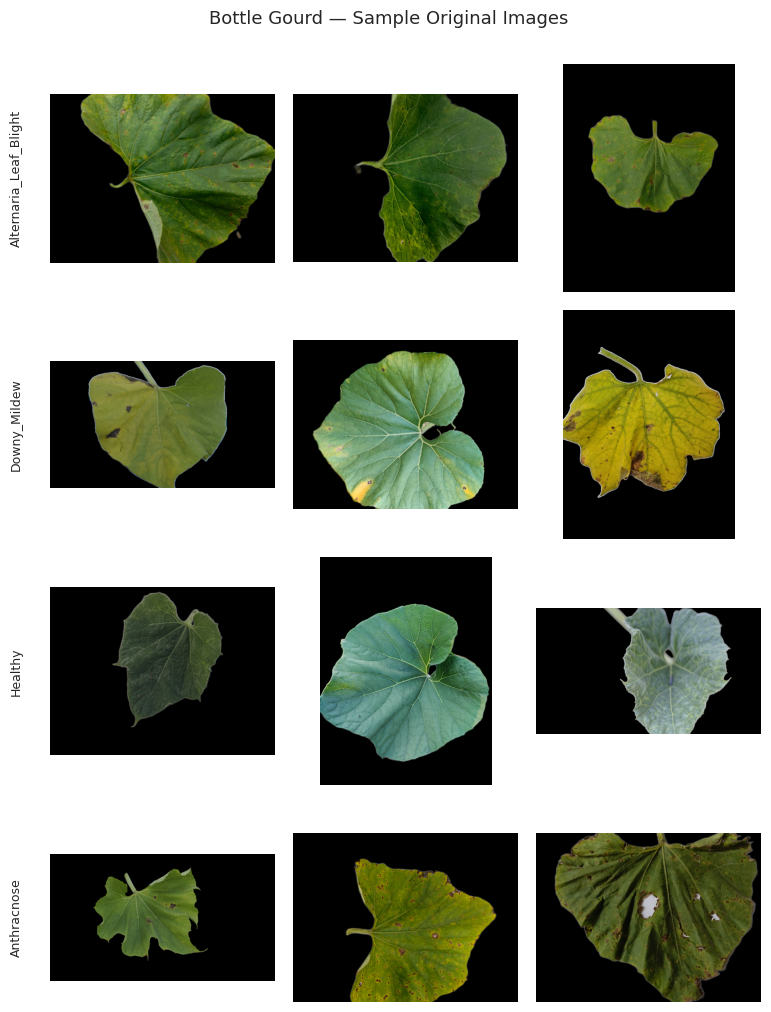

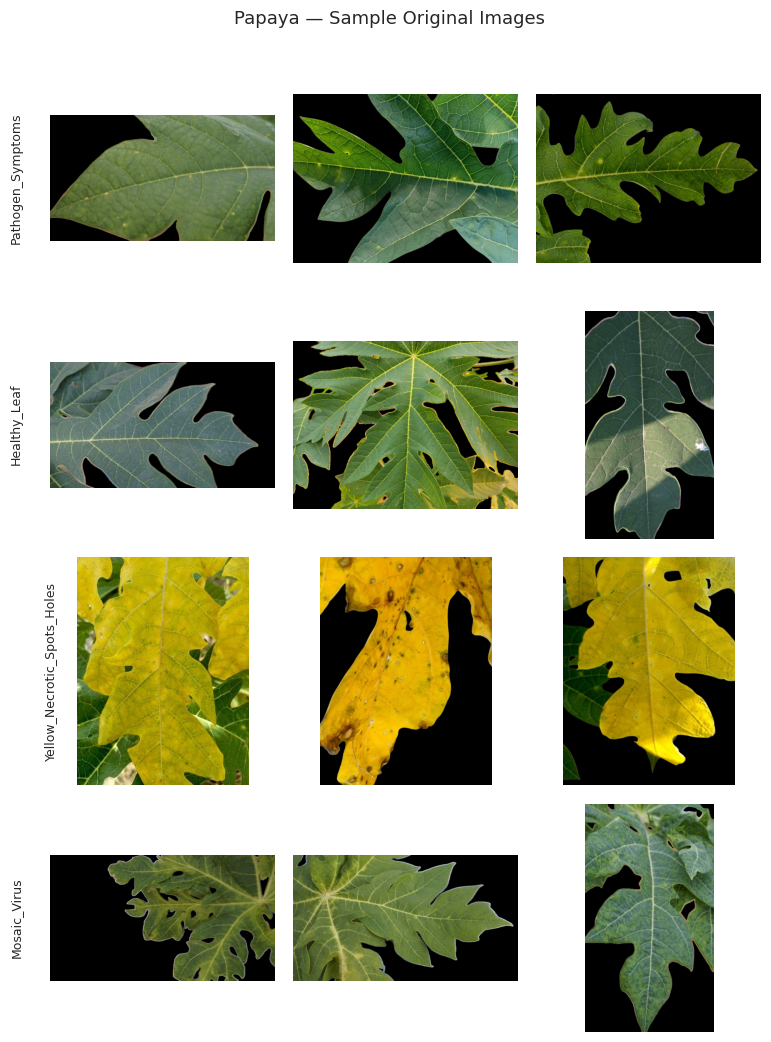

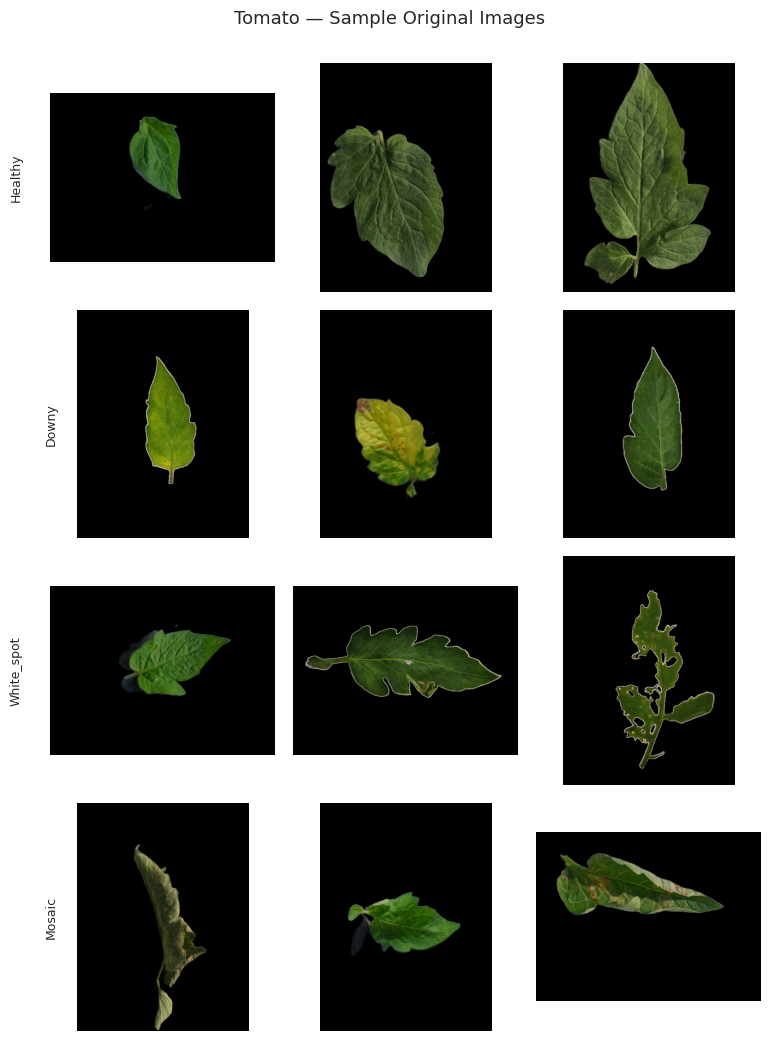

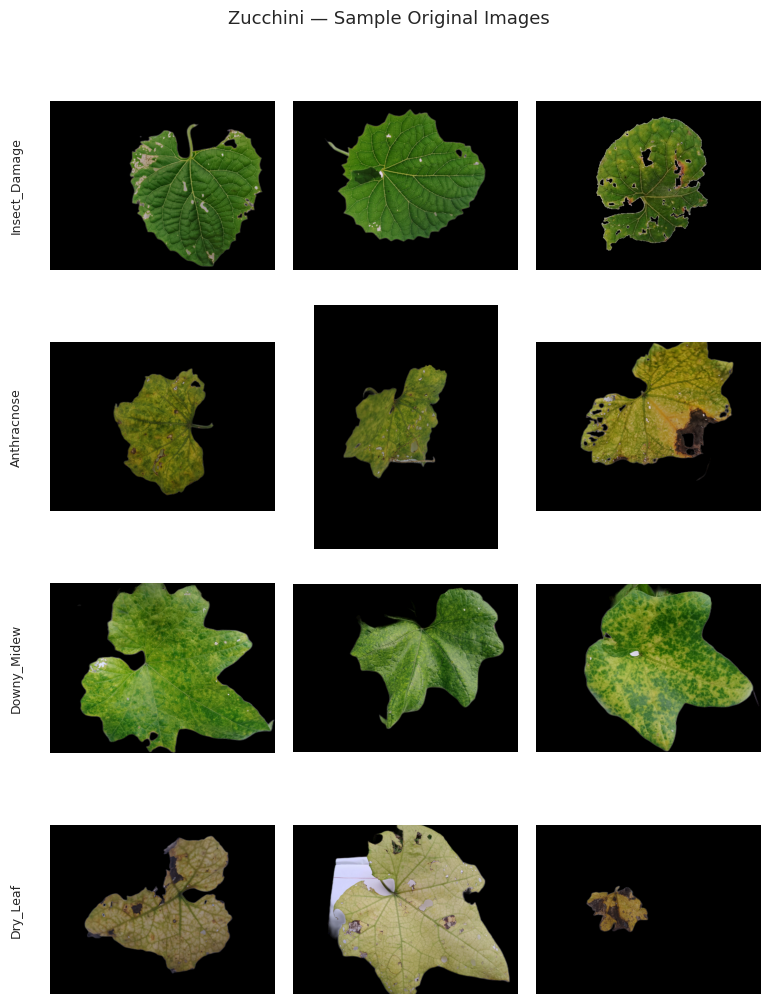

In [21]:
def show_sample_grid(dataframe, crop_name, split_name="Original", n_classes=4, n_per_class=3, seed=RNG_SEED):
    subset = dataframe[(dataframe["crop"] == crop_name) & (dataframe["split"] == split_name)]
    if subset.empty:
        print(f"No images found for crop='{crop_name}', split='{split_name}'.")
        return

    classes = subset["class_name"].unique()
    rs = np.random.RandomState(seed)
    chosen_classes = rs.choice(classes, size=min(n_classes, len(classes)), replace=False)

    fig, axes = plt.subplots(len(chosen_classes), n_per_class,
                              figsize=(n_per_class * 2.6, len(chosen_classes) * 2.6))
    axes = np.array(axes).reshape(len(chosen_classes), n_per_class)

    for row, cls in enumerate(chosen_classes):
        cls_paths = subset[subset["class_name"] == cls]["path"].tolist()
        chosen_paths = rs.choice(cls_paths, size=min(n_per_class, len(cls_paths)), replace=False)
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen_paths):
                try:
                    img = Image.open(chosen_paths[col]).convert("RGB")
                    ax.imshow(img)
                except Exception as e:
                    ax.text(0.5, 0.5, "unreadable", ha="center", va="center")
            ax.axis("off")
            if col == 0:
                prefix = crop_name.replace(" ", "_") + "_"
                display_cls = cls[len(prefix):] if cls.startswith(prefix) else cls
                ax.set_ylabel(display_cls, fontsize=9)
                ax.text(-0.15, 0.5, display_cls, fontsize=9, rotation=90,
                         va="center", ha="center", transform=ax.transAxes)

    plt.suptitle(f"{crop_name} — Sample {split_name} Images", fontsize=13, y=1.0)
    plt.tight_layout()
    safe_name = crop_name.lower().replace(" ", "_")
    plt.savefig(OUTPUT_DIR / f"08_sample_grid_{safe_name}_{split_name.lower()}.png", bbox_inches="tight")
    plt.show()


if len(df):
    for crop_name in sorted(df["crop"].unique()):
        show_sample_grid(df, crop_name, split_name="Original", n_classes=4, n_per_class=3)
else:
    print("No data available to render sample image grids.")

### 6.1 Original vs Augmented — Side-by-Side Comparison

To visually confirm what the augmentation pipeline (rotation, flips, brightness/
contrast jitter, Gaussian noise, sharpening — as described in the README) actually
does to the images, we compare a few Original images against Augmented images
from the *same* crop and class.

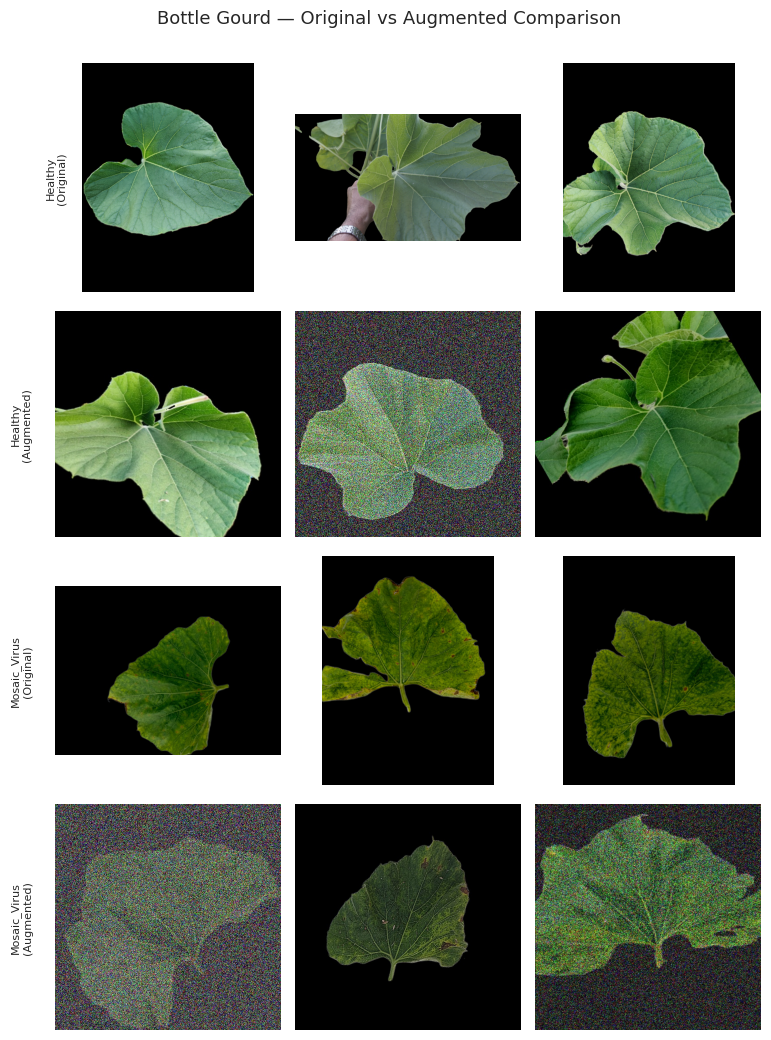

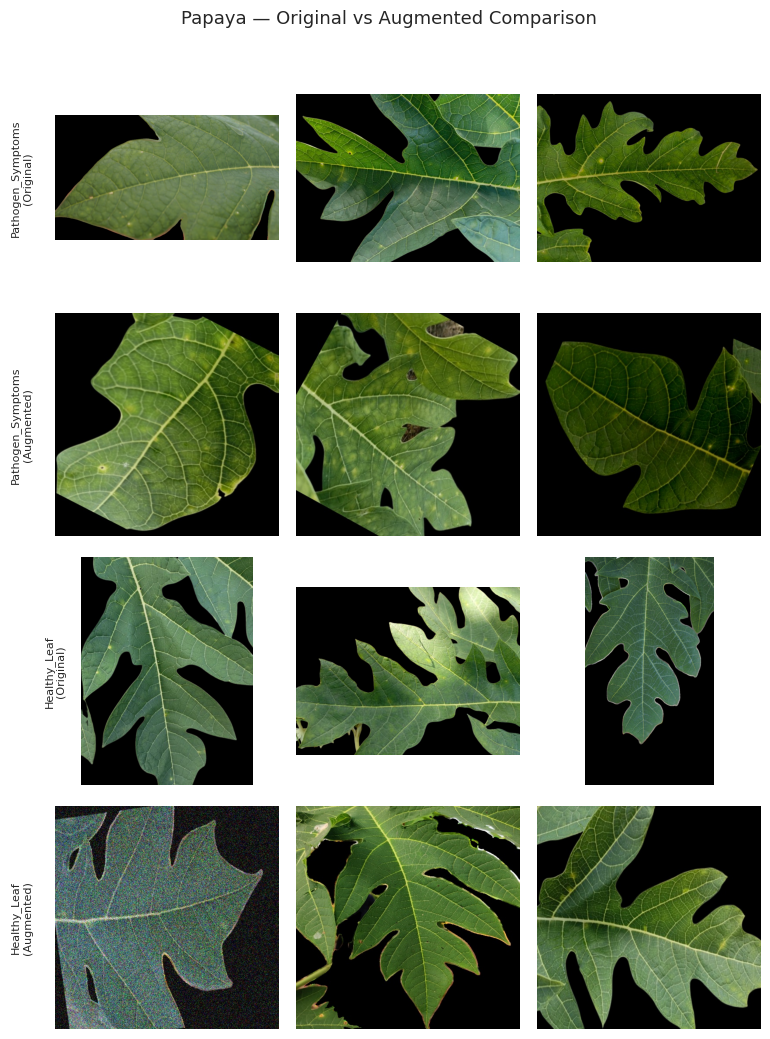

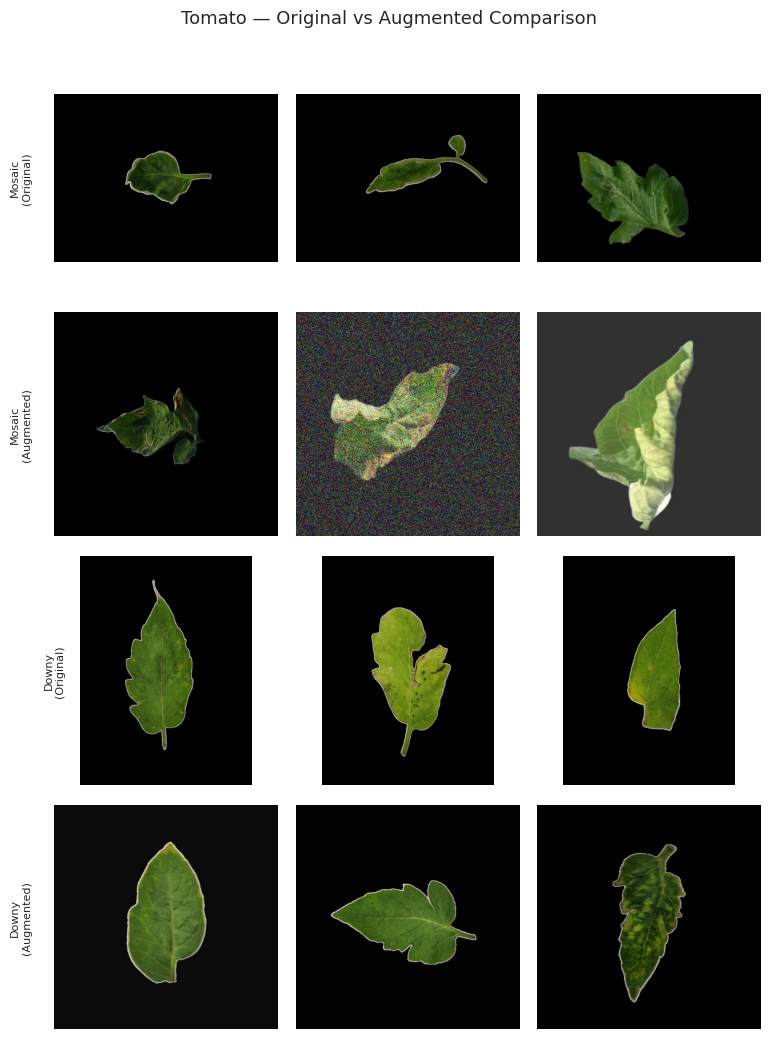

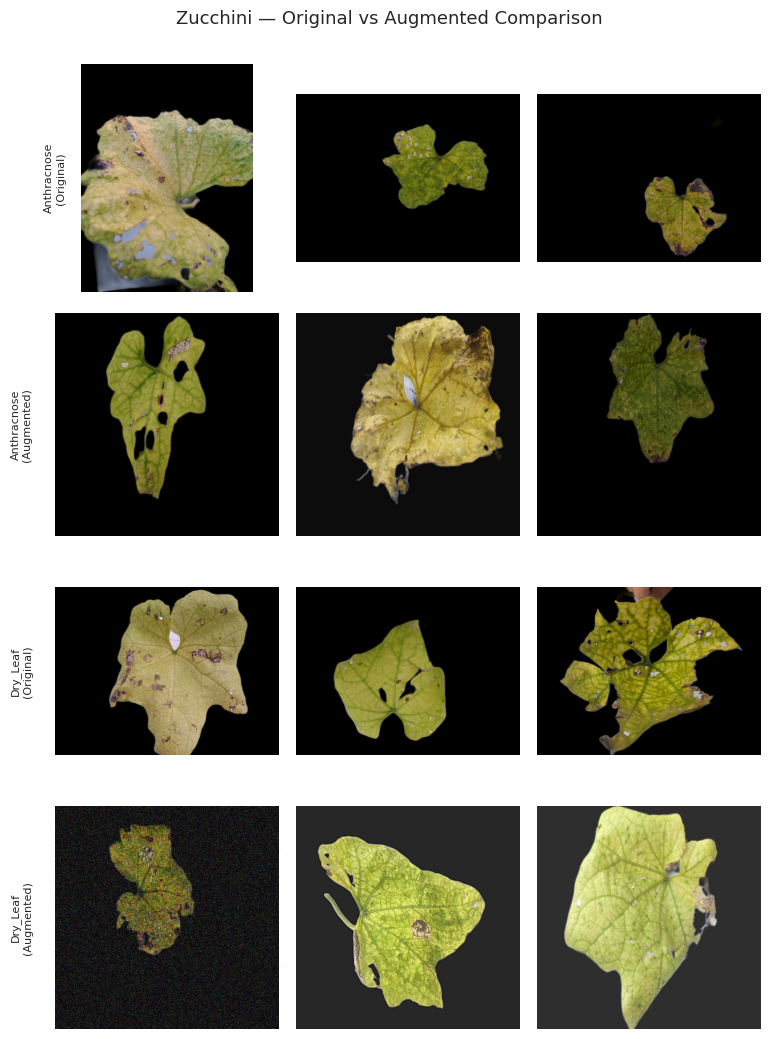

In [22]:
def show_original_vs_augmented(dataframe, crop_name, n_classes=2, n_per_class=3, seed=RNG_SEED):
    rs = np.random.RandomState(seed)
    crop_df = dataframe[dataframe["crop"] == crop_name]
    common_classes = (
        set(crop_df[crop_df["split"] == "Original"]["class_name"].unique())
        & set(crop_df[crop_df["split"] == "Augmented"]["class_name"].unique())
    )
    if not common_classes:
        print(f"No overlapping classes between Original/Augmented for crop '{crop_name}'.")
        return

    chosen_classes = rs.choice(list(common_classes), size=min(n_classes, len(common_classes)), replace=False)

    fig, axes = plt.subplots(len(chosen_classes) * 2, n_per_class,
                              figsize=(n_per_class * 2.6, len(chosen_classes) * 2 * 2.6))
    axes = np.array(axes).reshape(len(chosen_classes) * 2, n_per_class)

    for i, cls in enumerate(chosen_classes):
        for j, split in enumerate(["Original", "Augmented"]):
            row = i * 2 + j
            paths = crop_df[(crop_df["class_name"] == cls) & (crop_df["split"] == split)]["path"].tolist()
            chosen_paths = rs.choice(paths, size=min(n_per_class, len(paths)), replace=False) if paths else []
            for col in range(n_per_class):
                ax = axes[row, col]
                if col < len(chosen_paths):
                    try:
                        img = Image.open(chosen_paths[col]).convert("RGB")
                        ax.imshow(img)
                    except Exception:
                        ax.text(0.5, 0.5, "unreadable", ha="center", va="center")
                ax.axis("off")
                if col == 0:
                    prefix = crop_name.replace(" ", "_") + "_"
                    display_cls = cls[len(prefix):] if cls.startswith(prefix) else cls
                    ax.text(-0.15, 0.5, f"{display_cls}\n({split})", fontsize=8, rotation=90,
                             va="center", ha="center", transform=ax.transAxes)

    plt.suptitle(f"{crop_name} — Original vs Augmented Comparison", fontsize=13, y=1.0)
    plt.tight_layout()
    safe_name = crop_name.lower().replace(" ", "_")
    plt.savefig(OUTPUT_DIR / f"09_orig_vs_aug_{safe_name}.png", bbox_inches="tight")
    plt.show()


if len(df):
    for crop_name in sorted(df["crop"].unique()):
        show_original_vs_augmented(df, crop_name, n_classes=2, n_per_class=3)
else:
    print("No data available for original-vs-augmented comparison.")

## 7. Data Quality Checks

Two practical checks before using this data for modeling:
1. **Corrupt / unreadable files** — already flagged during property extraction (Section 4).
2. **Exact duplicate images** — detected via file hashing on the sampled subset.
   (Full-dataset hashing is the same idea, just slower; this can be extended by
   setting `SAMPLE_PER_GROUP` higher or running hashing over `df` instead of `sample_df`.)

In [23]:
def file_md5(path, block_size=8192):
    h = hashlib.md5()
    try:
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(block_size), b""):
                h.update(chunk)
        return h.hexdigest()
    except Exception:
        return None


print("(Note: this checks for byte-identical files. It will NOT catch transformed")
print("Augmented copies of an Original image — that is what the perceptual-hash")
print("leakage check in Section 5.2 is for. This check catches things like the same")
print("file being saved into two different class folders by mistake, or accidental")
print("re-exports.)")
print()

if len(full_df):
    print(f"Computing MD5 over the FULL dataset ({len(full_df):,} images) to detect "
          f"exact byte-identical duplicates...")
    full_df["md5"] = [file_md5(p) for p in tqdm(full_df["path"], desc="MD5 hashing")]
    dup_counts = full_df["md5"].value_counts()
    duplicates = dup_counts[dup_counts > 1]
    n_dup_groups = len(duplicates)
    n_dup_files = duplicates.sum() - n_dup_groups if n_dup_groups else 0

    print_table(
        f"FULL-DATASET exact-duplicate result: {n_dup_groups:,} duplicate groups, "
        f"{n_dup_files:,} redundant exact-copy files.",
        pd.Series(dtype=object),
    )

    if n_dup_groups:
        dup_examples = full_df[full_df["md5"].isin(duplicates.index)][
            ["crop", "split", "class_name", "path", "md5"]
        ].sort_values("md5")
        print_table("Example exact-duplicate file groups (first 20 rows):", dup_examples.head(20))

        # Flag the most actionable case: exact duplicates that span DIFFERENT
        # classes or different splits, since those are mislabeling / leakage
        # risks rather than harmless redundant copies within the same class.
        cross_class_dups = []
        for md5_val in duplicates.index:
            grp = full_df[full_df["md5"] == md5_val]
            if grp["class_name"].nunique() > 1 or grp["split"].nunique() > 1:
                cross_class_dups.append(grp)
        if cross_class_dups:
            cross_class_df = pd.concat(cross_class_dups)
            print_table(
                f"WARNING: {cross_class_df['md5'].nunique()} duplicate group(s) contain the exact "
                f"same file appearing under DIFFERENT classes or DIFFERENT splits — this is a "
                f"labeling/leakage risk, not just redundancy:",
                cross_class_df[["crop", "split", "class_name", "path", "md5"]].sort_values("md5"),
            )
        else:
            print("All exact-duplicate groups stay within a single class and split (redundant, not mislabeled).")
    else:
        print("No exact byte-identical duplicate files found across the entire dataset.")
else:
    print("No data available for duplicate-detection check.")


(Note: this checks for byte-identical files. It will NOT catch transformed
Augmented copies of an Original image — that is what the perceptual-hash
leakage check in Section 5.2 is for. This check catches things like the same
file being saved into two different class folders by mistake, or accidental
re-exports.)

Computing MD5 over the FULL dataset (28,121 images) to detect exact byte-identical duplicates...


MD5 hashing:   0%|          | 0/28121 [00:00<?, ?it/s]

────────────────────────────────────────────────────────────────────────
FULL-DATASET exact-duplicate result: 864 duplicate groups, 1,255 redundant exact-copy files.
────────────────────────────────────────────────────────────────────────

────────────────────────────────────────────────────────────────────────
Example exact-duplicate file groups (first 20 rows):
────────────────────────────────────────────────────────────────────────
            crop      split                                 class_name                                                   path                               md5
0   Bottle Gourd  Augmented  Bottle_Gourd_Early_Alternaria_Leaf_Blight             …/aug_Early_Alternaria_Leaf_Blight_195.jpg  006881f7323b12d01183f9c7517f0a53
1   Bottle Gourd  Augmented  Bottle_Gourd_Early_Alternaria_Leaf_Blight              …/aug_Early_Alternaria_Leaf_Blight_71.jpg  006881f7323b12d01183f9c7517f0a53
2         Papaya   Original                    Papaya_Bacterial_Blight      …/IMG

## 8. Key Findings & Summary

This section consolidates the headline observations from the analysis above into
a single readable report.

In [24]:
print("=" * 70)
print("EDA SUMMARY REPORT — Agri-Vision4 Multi-Crop Leaf Disease Dataset")
print("=" * 70)

print(f"\n[Dataset Scale]")
print(f"  Total images discovered  : {total_images:,}")
print(f"  Original images          : {n_original:,}")
print(f"  Augmented images         : {n_augmented:,}")
print(f"  Crops covered             : {', '.join(sorted(df['crop'].unique())) if len(df) else 'N/A'}")
print(f"  Total classes             : {df['class_name'].nunique() if len(df) else 0}")

if len(orig_df) and "imbalance_df" in dir():
    most_imbalanced = imbalance_df.iloc[0]
    print(f"\n[Class Balance — Original Images Only]")
    print(f"  Most imbalanced crop      : {most_imbalanced['crop']} "
          f"(ratio {most_imbalanced['imbalance_ratio']}x between largest & smallest class)")
    print(f"  Mean imbalance ratio      : {imbalance_df['imbalance_ratio'].mean():.2f}x across all crops")

if "full_imbalance_df" in dir() and len(full_imbalance_df):
    most_imbalanced_full = full_imbalance_df.iloc[0]
    print(f"\n[Class Balance — FULL DATASET (Original + Augmented)]")
    print(f"  Most imbalanced crop      : {most_imbalanced_full['crop']} "
          f"(ratio {most_imbalanced_full['imbalance_ratio']}x between largest & smallest class)")
    print(f"  Mean imbalance ratio      : {full_imbalance_df['imbalance_ratio'].mean():.2f}x across all crops")

if "full_df" in dir() and len(full_df):
    n_corrupt_total = int(full_df["corrupt"].sum())
    print(f"\n[Data Integrity — FULL DATASET, every image scanned]")
    print(f"  Corrupt/unreadable images : {n_corrupt_total:,} / {len(full_df):,} "
          f"({100 * n_corrupt_total / len(full_df):.3f}%)")

if "valid_full" in dir() and len(valid_full):
    pct_non_std_full = 100 * ((valid_full["width"] != 512) | (valid_full["height"] != 512)).mean()
    print(f"  Images not exactly 512x512: {pct_non_std_full:.2f}% (full dataset)")
    n_modes = valid_full["mode"].nunique()
    if n_modes > 1:
        print(f"  WARNING: {n_modes} distinct color modes found (expected just RGB) — see Section 3.4.1")

if "duplicates" in dir():
    n_dup_groups_full = len(duplicates) if hasattr(duplicates, "__len__") else 0
    print(f"\n[Exact Duplicate Files — FULL DATASET]")
    print(f"  Exact byte-identical duplicate groups: {n_dup_groups_full:,}")

if "leak_df" in dir():
    print(f"\n[Data Leakage Check — Original vs Augmented near-duplicates, FULL DATASET]")
    print(f"  Near-duplicate (leaked) Original/Augmented pairs found: {len(leak_df):,}")
    if len(leak_df):
        print(f"  Unique Original images implicated  : {leak_df['original_path'].nunique():,}")
        print(f"  Unique Augmented images implicated  : {leak_df['augmented_path'].nunique():,}")
        print(f"  Crops most affected                 : {', '.join(leak_df.groupby('crop').size().sort_values(ascending=False).index[:3])}")

if len(valid_sample):
    print(f"\n[Image Quality / Pixel Stats — sampled, brightness/contrast/sharpness only]")
    for split in ["Original", "Augmented"]:
        subset = valid_sample[valid_sample["split"] == split]
        if len(subset):
            print(f"  {split:10s} -> mean brightness: {subset['brightness'].mean():.1f}, "
                  f"mean contrast(std): {subset['std_dev'].mean():.1f}, "
                  f"mean file size: {subset['file_size_kb'].mean():.1f} KB")

print("\n" + "=" * 70)
print("RECOMMENDATIONS FOR MODELING")
print("=" * 70)
recs = []
if "leak_df" in dir() and len(leak_df):
    recs.append(
        "- LEAKAGE DETECTED: do not randomly split Original+Augmented images "
        "independently into train/val/test. Split on ORIGINAL images first, "
        "then keep each Original's augmented derivatives in the same split "
        "(or simplest: only generate/augment within the training split)."
    )
else:
    recs.append(
        "- No Original/Augmented near-duplicates detected by the pHash check above. "
        "This does not guarantee zero leakage (e.g. if augmentation is very aggressive) "
        "— confirm against the dataset README for how Augmented images were generated "
        "before assuming a random split is safe."
    )
if "full_imbalance_df" in dir() and len(full_imbalance_df) and full_imbalance_df["imbalance_ratio"].max() > 3:
    recs.append(
        "- Meaningful class imbalance remains even after augmentation in at least one "
        "crop. Consider class-weighted loss, oversampling minority classes, or "
        "stratified evaluation metrics (macro-F1) rather than plain accuracy."
    )
if "n_corrupt_total" in dir() and n_corrupt_total > 0:
    recs.append(
        f"- {n_corrupt_total} corrupt/unreadable files were found across the full dataset "
        f"— exclude or repair these before training (see Section 3.4 for exact paths)."
    )
if "pct_non_std_full" in dir() and pct_non_std_full > 0:
    recs.append(
        "- Not all images are a uniform size — confirm your training pipeline resizes/"
        "pads consistently rather than assuming 512x512 input."
    )
for r in recs:
    print(r)

print("\n" + "=" * 70)
print(f"All figures saved to: {OUTPUT_DIR.resolve()}")
print("=" * 70)


EDA SUMMARY REPORT — Agri-Vision4 Multi-Crop Leaf Disease Dataset

[Dataset Scale]
  Total images discovered  : 28,121
  Original images          : 5,246
  Augmented images         : 22,875
  Crops covered             : Bottle Gourd, Papaya, Tomato, Zucchini
  Total classes             : 28

[Class Balance — Original Images Only]
  Most imbalanced crop      : Papaya (ratio 10.55x between largest & smallest class)
  Mean imbalance ratio      : 6.80x across all crops

[Class Balance — FULL DATASET (Original + Augmented)]
  Most imbalanced crop      : Tomato (ratio 1.14x between largest & smallest class)
  Mean imbalance ratio      : 1.04x across all crops

[Data Integrity — FULL DATASET, every image scanned]
  Corrupt/unreadable images : 0 / 28,121 (0.000%)
  Images not exactly 512x512: 18.66% (full dataset)

[Exact Duplicate Files — FULL DATASET]
  Exact byte-identical duplicate groups: 864

[Data Leakage Check — Original vs Augmented near-duplicates, FULL DATASET]
  Near-duplicate (lea